**Cell 1 — Install and Import Libraries**

In [11]:
# CELL 1 — ENVIRONMENT SETUP
# Install only the additional libraries needed for PDF processing.

%pip -q install pymupdf tiktoken

import re
import json
import time
import random
import hashlib
from pathlib import Path
from importlib.metadata import version

import fitz
import tiktoken
import pandas as pd

from google import genai
from google.genai import types
from google.colab import userdata
from IPython.display import display, Markdown

print("TASK 1 — ENVIRONMENT READY")
print("Pandas:", pd.__version__)
print("Google GenAI:", version("google-genai"))
print("PyMuPDF:", version("pymupdf"))
print("Tokenizer: cl100k_base")
print("All required libraries imported successfully.")

TASK 1 — ENVIRONMENT READY
Pandas: 3.1.1
Google GenAI: 3.0.0
PyMuPDF: 2.1
Tokenizer: cl100k_base
All required libraries imported successfully.


**Cell 2 — Configuration and Gemini Initialization**

In [12]:
# CELL 2 — GEMINI CONFIGURATION AND RELIABLE API ACCESS

PDF_PATH = Path("/content/MOLDOVA.pdf")
OUTPUT_DIR = Path("/content/moldova_outputs")
CACHE_DIR = OUTPUT_DIR / "cache"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)

MODEL = "gemini-3.5-flash-lite"
CHUNK_SIZE = 400
CHUNK_OVERLAP = 50

# Check the PDF before starting any API requests.
if not PDF_PATH.is_file():
    raise FileNotFoundError(
        "MOLDOVA.pdf was not found in /content/. "
        "Check the Colab Files panel."
    )

# Access the existing secret without exposing its value.
API_KEY = userdata.get("GeminiAPI")

if not API_KEY:
    raise ValueError(
        "GeminiAPI is unavailable. Check Colab Secrets access."
    )

client = genai.Client(api_key=API_KEY)
tokenizer = tiktoken.get_encoding("cl100k_base")


def save_json(filename, data):
    """Save reproducible outputs for later assignment tasks."""
    path = OUTPUT_DIR / filename
    path.write_text(
        json.dumps(data, indent=2, ensure_ascii=False),
        encoding="utf-8"
    )
    return path


def ask_gemini(prompt, system_instruction,
               temperature=0.1, json_mode=False):
    """Call Gemini with caching and retries for temporary API errors."""

    request = {
        "model": MODEL,
        "prompt": prompt,
        "system": system_instruction,
        "temperature": temperature,
        "json_mode": json_mode
    }

    cache_id = hashlib.sha256(
        json.dumps(request, sort_keys=True).encode("utf-8")
    ).hexdigest()

    cache_file = CACHE_DIR / f"{cache_id}.txt"

    # Reuse earlier successful responses.
    if cache_file.exists():
        cached = cache_file.read_text(encoding="utf-8")
        if not json_mode:
            return cached
        try:
            json.loads(cached)
            return cached
        except json.JSONDecodeError:
            cache_file.unlink()

    config = types.GenerateContentConfig(
        system_instruction=system_instruction,
        temperature=temperature,
        response_mime_type=(
            "application/json" if json_mode else "text/plain"
        )
    )

    max_attempts = 6

    for attempt in range(max_attempts):
        try:
            response = client.models.generate_content(
                model=MODEL,
                contents=prompt,
                config=config
            )

            answer = (response.text or "").strip()

            if not answer:
                raise ValueError("Gemini returned an empty response.")

            # Validate JSON before accepting and caching it.
            if json_mode:
                json.loads(answer)

            cache_file.write_text(answer, encoding="utf-8")
            return answer

        except Exception as error:

            status = getattr(error, "code", None)

            # Retry only temporary API failures.
            retryable = status in (429, 500, 502, 503, 504)

            if not retryable:
                raise

            if attempt == max_attempts - 1:
                raise RuntimeError(
                    f"Gemini API unavailable after {max_attempts} attempts. "
                    f"Last error: {error}"
                ) from error

            # Exponential backoff with jitter reduces repeated collisions.
            delay = min(4 * (2 ** attempt), 40)
            delay += random.uniform(0, 2)

            print(
                f"Temporary API error {status}. "
                f"Retry {attempt + 1}/{max_attempts - 1}."
            )

            time.sleep(delay)


print("GEMINI CONFIGURATION")
print("PDF:", PDF_PATH.name)
print("Model:", MODEL)
print("API secret:", "GeminiAPI")
print("Chunk size:", CHUNK_SIZE)
print("Overlap:", CHUNK_OVERLAP)
print("Caching:", "Enabled")
print("Retry handling:", "Enabled")
print("Configuration successful.")

GEMINI CONFIGURATION
PDF: MOLDOVA.pdf
Model: gemini-3.5-flash-lite
API secret: GeminiAPI
Chunk size: 400
Overlap: 50
Caching: Enabled
Retry handling: Enabled
Configuration successful.


**Cell 3 — PDF Extraction and Text Cleaning**

In [13]:
# CELL 3 — PDF EXTRACTION AND CLEANING

document = fitz.open(str(PDF_PATH))

if len(document) == 0:
    raise ValueError("The PDF contains zero pages.")

raw_pages = [
    page.get_text("text", sort=True)
    for page in document
]

document.close()

if not any(text.strip() for text in raw_pages):
    raise ValueError("No readable text was extracted.")


def clean_text(text):
    """Clean common PDF artifacts while preserving financial values."""

    text = text.replace("\u00ad", "").replace("\xa0", " ")

    # Repair words broken across PDF line boundaries.
    text = re.sub(r"(?<=\w)-\n(?=[a-z])", "", text)

    # Remove repeated standalone publication headers.
    text = re.sub(
        r"(?im)^\s*(REPUBLIC OF MOLDOVA|"
        r"INTERNATIONAL MONETARY FUND)\s*$",
        "",
        text
    )

    # Remove excess whitespace without destroying table rows.
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\n{3,}", "\n\n", text)

    return text.strip()


pages = [
    {
        "page": index + 1,
        "text": clean_text(raw)
    }
    for index, raw in enumerate(raw_pages)
]

full_text = "\n\n".join(
    f"[PDF PAGE {page['page']}]\n{page['text']}"
    for page in pages
)

if len(full_text) < 1000:
    raise ValueError("Extracted report text is unexpectedly short.")

(OUTPUT_DIR / "cleaned_report.txt").write_text(
    full_text,
    encoding="utf-8"
)

pdf_statistics = {
    "filename": PDF_PATH.name,
    "total_pages": len(pages),
    "pages_with_text": sum(bool(p["text"]) for p in pages),
    "raw_characters": sum(len(text) for text in raw_pages),
    "cleaned_characters": len(full_text),
    "estimated_tokens": len(tokenizer.encode(full_text))
}

save_json("pdf_statistics.json", pdf_statistics)

print("PDF EXTRACTION RESULTS")
display(
    pd.DataFrame(
        pdf_statistics.items(),
        columns=["Metric", "Value"]
    )
)

print("\nCLEANED DOCUMENT PREVIEW")
print(full_text[:1200])

print("\nPDF extraction completed.")

PDF EXTRACTION RESULTS


,Metric,Value
0,filename,MOLDOVA.pdf
1,total_pages,100
2,pages_with_text,100
3,raw_characters,453514
4,cleaned_characters,253390
5,estimated_tokens,65569



CLEANED DOCUMENT PREVIEW
[PDF PAGE 1]
IMF Country Report No. 26/59

 2025 ARTICLE IV CONSULTATION—PRESS RELEASE;
March 2026 STAFF REPORT; AND STATEMENT BY THE ALTERNATE
 EXECUTIVE DIRECTOR FOR REPUBLIC OF MOLDOVA

 Under Article IV of the IMF’s Articles of Agreement, the IMF holds bilateral discussions
 with members, usually every year. In the context of the 2025 Article IV consultation with
 the Republic of Moldova, the following documents have been released and are included in
 this package:

 • A Press Release summarizing the views of the Executive Board as expressed during its
 February 27, 2026, consideration of the staff report that concluded the Article IV
 consultation with the Republic of Moldova.

 • The Staff Report prepared by a staff team of the IMF for the Executive Board’s
 consideration on February 27, 2026, following discussions that ended on December
 17, with the officials of the Republic of Moldova on economic developments and
 policies. Based on information availa

**Cell 4 — Token-Aware Chunking**

In [14]:
# CELL 4 — TOKEN-AWARE TEXT CHUNKING

def create_chunks(page_records, chunk_size=400, overlap=50):
    """Split PDF pages into traceable, overlapping token chunks."""

    if not 0 < overlap < chunk_size:
        raise ValueError("Overlap must be smaller than chunk size.")

    results = []
    chunk_id = 1

    for page in page_records:

        tokens = tokenizer.encode(page["text"])

        if not tokens:
            continue

        step = chunk_size - overlap

        for start in range(0, len(tokens), step):

            segment = tokens[start:start + chunk_size]

            if not segment:
                break

            results.append({
                "chunk_id": chunk_id,
                "page": page["page"],
                "token_count": len(segment),
                "text": tokenizer.decode(segment)
            })

            chunk_id += 1

            if start + chunk_size >= len(tokens):
                break

    return results


chunks = create_chunks(
    pages,
    chunk_size=CHUNK_SIZE,
    overlap=CHUNK_OVERLAP
)

if not chunks:
    raise ValueError("No text chunks were generated.")

save_json("document_chunks.json", chunks)

chunk_lengths = [chunk["token_count"] for chunk in chunks]

chunk_statistics = {
    "total_chunks": len(chunks),
    "target_chunk_size": CHUNK_SIZE,
    "overlap_tokens": CHUNK_OVERLAP,
    "minimum_tokens": min(chunk_lengths),
    "maximum_tokens": max(chunk_lengths),
    "average_tokens": round(
        sum(chunk_lengths) / len(chunk_lengths), 2
    )
}

save_json("chunk_statistics.json", chunk_statistics)

print("CHUNKING RESULTS")

display(
    pd.DataFrame(
        chunk_statistics.items(),
        columns=["Metric", "Value"]
    )
)

print("\nSAMPLE CHUNK")
print("Chunk ID:", chunks[0]["chunk_id"])
print("PDF page:", chunks[0]["page"])
print("Tokens:", chunks[0]["token_count"])
print(chunks[0]["text"][:800])

print("\nToken-aware chunking completed.")

CHUNKING RESULTS


,Metric,Value
0,total_chunks,226.00
1,target_chunk_size,400.00
2,overlap_tokens,50.00
3,minimum_tokens,7.00
4,maximum_tokens,400.00
5,average_tokens,314.95



SAMPLE CHUNK
Chunk ID: 1
PDF page: 1
Tokens: 400
IMF Country Report No. 26/59

 2025 ARTICLE IV CONSULTATION—PRESS RELEASE;
March 2026 STAFF REPORT; AND STATEMENT BY THE ALTERNATE
 EXECUTIVE DIRECTOR FOR REPUBLIC OF MOLDOVA

 Under Article IV of the IMF’s Articles of Agreement, the IMF holds bilateral discussions
 with members, usually every year. In the context of the 2025 Article IV consultation with
 the Republic of Moldova, the following documents have been released and are included in
 this package:

 • A Press Release summarizing the views of the Executive Board as expressed during its
 February 27, 2026, consideration of the staff report that concluded the Article IV
 consultation with the Republic of Moldova.

 • The Staff Report prepared by a staff team of the IMF for the Executive Board’s
 consideration on February 27, 2026, fo

Token-aware chunking completed.


**Cell 5 — Executive Summary and Section Summarisation**

In [15]:
# CELL 5 — EXECUTIVE AND SECTION SUMMARISATION

# Boundaries correspond to PDF page numbers in MOLDOVA.pdf.
# The report's printed page numbers are different.

section_ranges = [
    ("Press Release and Executive Board Assessment", 2, 5),
    ("Key Issues and Staff Report Overview", 6, 8),
    ("Context", 9, 10),
    ("Recent Developments", 11, 14),
    ("Outlook and Risks", 15, 15),
    ("Fiscal Policy", 16, 19),
    ("Monetary and Exchange Rate Policy", 20, 21),
    ("Financial Sector Policies", 22, 23),
    ("Structural Reforms", 24, 26),
    ("Staff Appraisal", 27, 28),
    ("Economic Figures", 29, 33),
    ("Statistical Tables", 34, 41),
    ("Annex I: EU Growth Plan", 42, 44),
    ("Annex II: ECF-EFF and RSF Reforms", 45, 47),
    ("Annex III: Past Policy Recommendations", 48, 50),
    ("Annex IV: FSAP Recommendations", 51, 52),
    ("Annex V: External Sector Assessment", 53, 55),
    ("Annex VI: Risk Assessment Matrix", 56, 58),
    ("Annex VII: Capital Spending", 59, 61),
    ("Annex VIII: Distributed Profit Tax", 62, 65),
    ("Annex IX: Data Issues", 66, 67),
    ("Informational Annex", 68, 73),
    ("Debt Sustainability Analysis", 74, 95),
    ("Alternate Executive Director Statement", 96, 100)
]

# Confirm that the defined sections cover every substantive PDF page.
covered = [
    page
    for _, start, end in section_ranges
    for page in range(start, end + 1)
]

assert sorted(covered) == list(range(2, len(pages) + 1))


ANALYST_SYSTEM = """
You are a careful IMF macroeconomic research analyst.

Use only the supplied Moldova IMF report evidence.
Never invent numerical values, recommendations or source references.
Preserve measurement units, dates and reporting periods.
Distinguish historical observations from IMF projections.
Explain uncertainty instead of guessing.
Use concise, objective academic language.
"""


def get_section_text(start, end):
    """Retrieve a report section with its original PDF page references."""
    return "\n\n".join(
        f"[PDF PAGE {p['page']}]\n{p['text']}"
        for p in pages[start - 1:end]
    )


def split_evidence(text, max_tokens=3500):
    """Divide long evidence into manageable token-limited segments."""
    token_ids = tokenizer.encode(text)

    return [
        tokenizer.decode(token_ids[i:i + max_tokens])
        for i in range(0, len(token_ids), max_tokens)
    ]


def summarise_section(name, start, end):
    """Summarise all section evidence without discarding later passages."""

    source = get_section_text(start, end)
    parts = split_evidence(source)
    evidence_notes = []

    # Long sections receive a complete evidence-extraction pass.
    for number, part in enumerate(parts, 1):

        if len(parts) == 1:
            evidence_notes.append(part)
            continue

        prompt = f"""
        Section: {name}
        Part: {number} of {len(parts)}

        Extract the important evidence from this IMF passage.

        Include:
        - Key economic findings.
        - Important numerical indicators and their dates.
        - Risks, policy recommendations and limitations.
        - Available PDF page references.

        Maximum 150 words.
        Do not invent or infer unsupported values.

        SOURCE:
        {part}
        """

        note = ask_gemini(prompt, ANALYST_SYSTEM)
        evidence_notes.append(note)

    evidence = "\n\n".join(evidence_notes)

    prompt = f"""
    Summarise this IMF report section.

    SECTION: {name}

    Requirements:
    - Write one paragraph of no more than 85 words.
    - Include the most important source-supported findings.
    - Preserve dates, units and forecast distinctions.
    - Mention relevant risks and policy implications.
    - Avoid repetition and unsupported claims.
    - Return the summary only.

    EVIDENCE:
    {evidence}
    """

    summary = ask_gemini(prompt, ANALYST_SYSTEM)

    # Enforce the assignment's strict fewer-than-100-word requirement.
    for _ in range(2):

        if len(summary.split()) < 100:
            break

        summary = ask_gemini(
            "Rewrite the following in fewer than 90 words. "
            "Preserve factual accuracy and return only the paragraph:\n\n"
            + summary,
            ANALYST_SYSTEM,
            temperature=0
        )

    word_count = len(summary.split())

    if word_count >= 100:
        raise ValueError(
            f"Summary exceeds the 99-word limit: {name}"
        )

    return {
        "section": name,
        "start_page": start,
        "end_page": end,
        "source_parts": len(parts),
        "word_count": word_count,
        "summary": summary
    }


section_summaries = []

print("GENERATING MAJOR-SECTION SUMMARIES\n")

for index, (name, start, end) in enumerate(section_ranges, 1):

    result = summarise_section(name, start, end)
    section_summaries.append(result)

    # Save progress so completed work is preserved.
    save_json("section_summaries.json", section_summaries)

    print(
        f"{index:02d}/{len(section_ranges)} | "
        f"{name} | {result['word_count']} words"
    )


# Combine all section summaries to construct a report-wide overview.
report_evidence = "\n\n".join(
    f"{item['section']} "
    f"(PDF pages {item['start_page']}-{item['end_page']}): "
    f"{item['summary']}"
    for item in section_summaries
)

executive_prompt = f"""
Prepare a concise executive summary of the complete
Republic of Moldova 2025 IMF Article IV Consultation.

Provide 7 bullet points covering:

1. Economic recovery and GDP outlook.
2. Inflation and monetary policy.
3. Banking stability and credit conditions.
4. Fiscal position and public debt.
5. External balances and vulnerabilities.
6. Structural reforms and EU growth opportunities.
7. Principal financial risks and policy priorities.

Use only the supplied report-wide evidence.
Include relevant verified numbers, reporting years and units.
Distinguish economic forecasts from historical observations.
Avoid unsupported interpretations.

REPORT EVIDENCE:
{report_evidence}
"""

executive_summary = ask_gemini(
    executive_prompt,
    ANALYST_SYSTEM
)

save_json(
    "executive_summary.json",
    {
        "country": "Republic of Moldova",
        "report": "2025 Article IV Consultation",
        "model": MODEL,
        "summary": executive_summary
    }
)

print("\n" + "=" * 55)
print("EXECUTIVE SUMMARY")
print("=" * 55)

display(Markdown(executive_summary))

print("\n" + "=" * 55)
print("MAJOR-SECTION SUMMARIES")
print("=" * 55)

for item in section_summaries:

    display(Markdown(
        f"**{item['section']} "
        f"({item['word_count']} words)**\n\n"
        f"{item['summary']}"
    ))

print("\nSUMMARY VALIDATION")
print("Total sections:", len(section_summaries))
print(
    "All summaries under 100 words:",
    all(item["word_count"] < 100 for item in section_summaries)
)

print("Section and executive summaries saved successfully.")

GENERATING MAJOR-SECTION SUMMARIES

01/24 | Press Release and Executive Board Assessment | 80 words
02/24 | Key Issues and Staff Report Overview | 75 words
03/24 | Context | 76 words
04/24 | Recent Developments | 84 words
05/24 | Outlook and Risks | 73 words
06/24 | Fiscal Policy | 81 words
Temporary API error 503. Retry 1/5.
07/24 | Monetary and Exchange Rate Policy | 78 words
08/24 | Financial Sector Policies | 77 words
09/24 | Structural Reforms | 81 words
Temporary API error 503. Retry 1/5.
10/24 | Staff Appraisal | 86 words
11/24 | Economic Figures | 82 words
Temporary API error 503. Retry 1/5.
12/24 | Statistical Tables | 89 words
13/24 | Annex I: EU Growth Plan | 92 words
14/24 | Annex II: ECF-EFF and RSF Reforms | 75 words
15/24 | Annex III: Past Policy Recommendations | 81 words
16/24 | Annex IV: FSAP Recommendations | 74 words
17/24 | Annex V: External Sector Assessment | 86 words
18/24 | Annex VI: Risk Assessment Matrix | 76 words
19/24 | Annex VII: Capital Spending | 78 wor

Here is a concise executive summary of the Republic of Moldova 2025 IMF Article IV Consultation, based exclusively on the provided report evidence:

1. **Economic Recovery and GDP Outlook:**
   - *Historical Observations:* Moldova’s gradual recovery achieved 1.9 percent growth in 2025Q1–Q3, driven by a good harvest, robust domestic demand, wholesale and retail turnover, positive real wage growth, and low unemployment, despite an energy crisis and regional shocks.
   - *IMF Projections:* Real GDP growth is projected at 2.7 percent for 2025 and 2.3 percent in 2026, with medium-term potential growth expected to reach 3.5 percent, supported by EU accession and the EU Growth Plan.

2. **Inflation and Monetary Policy:**
   - *Historical Observations:* Headline inflation averaged 7.8 percent in 2025, peaking at 9.1 percent in January. January 2026 annual inflation was reported at 4.85 percent.
   - *IMF Projections:* Inflation is expected to return to the National Bank of Moldova’s (NBM) 5 ± 1.5 percent target range in early 2026 (hitting the 5 percent target). 
   - *Policy Priorities:* IMF staff advised a cautious, state-contingent monetary strategy and advised against the latest policy rate cut to manage lingering inflation risks, expanding bank lending, and an increasing output gap.

3. **Banking Stability and Credit Conditions:**
   - *Historical Observations:* Financial sector profitability remains high, capitalization is healthy (though declining), and non-performing loans stay low despite increasing real estate exposure. 
   - *Policy Priorities:* To address rapid credit growth, the NBM tightened its macroprudential stance by raising the countercyclical capital buffer by 0.5 percentage points effective January 2026 and another 1 percentage point to 1.5 percent effective May 2026. FSAP stress tests indicate banks can withstand severe scenarios with 0.6 percent of GDP in recapitalization needs.

4. **Fiscal Position and Public Debt:**
   - *Historical Observations:* Public and publicly guaranteed debt reached 38.8 percent of GDP in 2024, and Moldova maintains a low risk of external debt distress and moderate overall public debt distress.
   - *IMF Projections:* The fiscal deficit is projected to widen to 4.8 percent of GDP in 2026 due to scaled-up capital spending and increased current expenditures (including a wage structure reform estimated at 0.3 percent of GDP). Baseline projections indicate public debt will rise to 43 percent by 2030 and 44 percent of GDP by 2035.

5. **External Balances and Vulnerabilities:**
   - *Historical Observations:* The current account deficit widened to 16.6 percent of GDP in 2024 and reached 19.5 percent of GDP in 2025Q1–Q3, driven by sluggish exports, higher food and energy imports, and declining remittances. Staff assess the real effective exchange rate to be overvalued by about 40 percent.
   - *IMF Projections:* The current account deficit is projected to reach 19.6 percent of GDP in 2025 and 2026. External sustainability and debt distress risks remain low.

6. **Structural Reforms and EU Growth Opportunities:**
   - *Historical Observations:* Informal employment declined from 23.1 percent in 2023 to 20.6 percent in 2024. The European Commission’s 2025–27 Growth Plan provides Moldova with €1.885 billion (11.2 percent of 2024 GDP) in grants and concessional loans. 
   - *Policy Priorities:* To support the pro-growth government's aim to complete EU accession negotiations by 2028, Moldova requires ambitious structural reforms, enhanced anti-corruption enforcement (such as operationalizing anti-corruption tribunals), public financial management reforms, and calibrated minimum wage increases to combat historical labor supply pressures (such as a 2025H1 labor force participation rate of 40.8 percent).

7. **Principal Financial Risks and Policy Priorities:**
   - *Uncertainty & Downside Risks:* Key downside risks include regional geopolitical developments, the war in Ukraine, electricity import vulnerabilities from Ukrainian infrastructure damage, EU Growth Plan implementation delays, capital spending under-execution, real estate corrections, and financing shortfalls.
   - *Policy Priorities:* Authorities requested a three-year Policy Coordination Instrument (PCI) in January 2026 to anchor structural reforms. Priorities include prudent macroeconomic policies, revenue mobilization, stronger institutions, cash and debt management improvements, and strict monitoring of external financing efficiencies.


MAJOR-SECTION SUMMARIES


**Press Release and Executive Board Assessment (80 words)**

Moldova’s economy is recovering from multiple shocks, with IMF staff projecting real GDP growth at 2.7 percent in 2025 and 2.3 percent in 2026. The fiscal deficit is projected to widen to 4.8 percent of GDP in 2026 amid scaled-up capital spending, while inflation is expected to remain within the National Bank of Moldova’s 5 +/- 1.5 percent target range. Key downside risks include regional geopolitical developments and EU Growth Plan implementation delays, requiring prudent macroeconomic policies and structural reforms.

**Key Issues and Staff Report Overview (75 words)**

Moldova’s recovery from multiple shocks is underway, with growth projected at 2.7 percent in 2025 and 2.3 percent in 2026, and medium-term potential growth at 3.5 percent. Inflation should return to the 5 ± 1.5 percent corridor in early 2026. Downside risks involve geopolitical developments regarding Ukraine and EU Growth Plan implementation delays. Staff advise state-contingent monetary policy, tighter macroprudential borrower-based measures, structural anti-corruption reforms, and investment-driven fiscal reforms requiring stronger institutions and higher revenues.

**Context (76 words)**

Moldova, the poorest EU accession country, faces structural challenges, high poverty, and lingering impacts from multiple shocks. The newly formed pro-growth government aims to complete accession negotiations by 2028, backed by the EU accession and Growth Plan which provides significant financing in 2025–27 (11.2 percent of 2024 GDP). While previous IMF arrangements helped preserve macroeconomic stability, fiscal and governance reforms lagged. To ensure macroeconomic stability and enhance resilience, Moldova requires prudent policies and ambitious structural reforms.

... (18 outputs left out)

**Informational Annex (78 words)**

As of December 31, 2025, Moldova’s total IMF outstanding purchases and loans reached SDR 716.63 million. Forthcoming payments are projected at SDR 67.07 million for 2026 and SDR 81.14 million for 2027. The National Bank of Moldova maintains sound operational controls, with all September 2020 safeguards recommendations implemented and legislative amendments reinforcing institutional autonomy. Moldova classifies its de jure and de facto exchange rate arrangements as floating, with the NBM intervening in the interbank market to mitigate imbalances.

**Debt Sustainability Analysis (79 words)**

Moldova maintains a low risk of external debt distress and moderate overall public debt distress, with public and publicly guaranteed debt reaching 38.8 percent of GDP in 2024. Baseline projections indicate public debt will rise to 43 percent by 2030 and 44 percent of GDP by 2035. Downside risks include war spillovers, energy shocks, and severe real GDP growth shocks that could breach debt benchmarks. Policy priorities involve enhancing fiscal discipline, broadening growth drivers, and developing domestic debt markets.

**Alternate Executive Director Statement (89 words)**

Moldovan authorities requested a three-year Policy Coordination Instrument (PCI) in January 2026 to anchor structural reforms and support EU integration following strong progress in the bilateral screening process. Growth is projected to gradually recover toward potential, driven by EU Growth Plan investments, though downside risks remain prominent due to Russia's war in Ukraine, geopolitical tensions, and energy disruptions. Monetary policy remains data-dependent, with January 2026 annual inflation at 4.85 percent. Macroprudential tightening addresses credit and real estate risks, while a temporarily higher 2026 fiscal deficit accommodates capital investment needs.


SUMMARY VALIDATION
Total sections: 24
All summaries under 100 words: True
Section and executive summaries saved successfully.


**Cell 6 — LLM-as-a-Judge Quality Evaluation**

In [16]:
# CELL 6 — LLM-AS-A-JUDGE AND TASK 1 VALIDATION

JUDGE_SYSTEM = """
You are a critical academic evaluator of IMF report summaries.

Evaluate the analyst's output against the supplied source evidence.
Do not assume that the analyst's statements are correct.

Score three dimensions from 1 to 5:

1. consistency:
Logical coherence and absence of contradictory statements.

2. completeness:
Coverage of important source findings and risks.

3. factual_alignment:
Accuracy of numerical values, reporting periods,
financial definitions and narrative claims.

Scoring:
1 = Poor
2 = Weak
3 = Acceptable
4 = Good
5 = Excellent

Identify unsupported claims and important omissions.

Return valid JSON containing exactly these fields:
consistency, completeness, factual_alignment,
unsupported_claims, missing_information, explanation.

Scores must be integers from 1 to 5.
Issue fields must be arrays of strings.
Be objective and do not invent source evidence.
"""


def select_judge_evidence(text, max_tokens=4200):
    """Select original-source evidence across a long section."""

    tokens = tokenizer.encode(text)

    if len(tokens) <= max_tokens:
        return text

    # Sample beginning, middle and end to improve section coverage.
    sample_size = max_tokens // 3
    middle = max(0, len(tokens) // 2 - sample_size // 2)

    positions = [
        0,
        middle,
        len(tokens) - sample_size
    ]

    samples = [
        tokenizer.decode(tokens[pos:pos + sample_size])
        for pos in positions
    ]

    return "\n\n[SEPARATE SOURCE EXCERPT]\n\n".join(samples)


def evaluate_summary(title, summary, evidence):
    """Evaluate a summary using the separate Gemini judge framework."""

    prompt = f"""
    Evaluate the following IMF report summary.

    SECTION:
    {title}

    ORIGINAL IMF SOURCE EVIDENCE:
    {evidence}

    GENERATED SUMMARY:
    {summary}

    Evaluate consistency, completeness and factual alignment.

    Important:
    - Penalise unsupported numerical claims.
    - Identify significant information missing from the summary.
    - Distinguish observations from economic projections.
    - Do not claim that unprovided source passages have been verified.
    - Return only the required JSON object.
    """

    response = ask_gemini(
        prompt,
        JUDGE_SYSTEM,
        temperature=0,
        json_mode=True
    )

    result = json.loads(response)

    # Validate the three numerical judge scores.
    for field in [
        "consistency",
        "completeness",
        "factual_alignment"
    ]:

        value = result.get(field)

        if type(value) is not int or not 1 <= value <= 5:
            raise ValueError(
                f"Invalid evaluation score for {field}: {value}"
            )

    # Validate issue lists instead of silently ignoring malformed output.
    for field in ["unsupported_claims", "missing_information"]:

        if not isinstance(result.get(field), list):
            raise ValueError(
                f"Invalid evaluation field: {field}"
            )

    return result


evaluations = []

print("EVALUATING MAJOR-SECTION SUMMARIES\n")

for index, item in enumerate(section_summaries, 1):

    source = get_section_text(
        item["start_page"],
        item["end_page"]
    )

    evidence = select_judge_evidence(source)

    audit = evaluate_summary(
        item["section"],
        item["summary"],
        evidence
    )

    record = {
        "section": item["section"],
        "pages": f"{item['start_page']}-{item['end_page']}",
        "word_count": item["word_count"],
        "word_limit_pass": item["word_count"] < 100,
        "source_sampling": (
            "full" if evidence == source else "sampled"
        ),
        **audit
    }

    evaluations.append(record)

    # Preserve completed evaluations.
    save_json("section_evaluations.json", evaluations)

    print(
        f"{index:02d}/{len(section_summaries)} | "
        f"{item['section']} | "
        f"Factual score: {audit['factual_alignment']}/5"
    )


# Evaluate the executive summary against report-wide summaries.
executive_audit = evaluate_summary(
    "Complete IMF Report — Executive Summary",
    executive_summary,
    report_evidence
)

save_json("executive_evaluation.json", executive_audit)

evaluation_df = pd.DataFrame(evaluations)

score_columns = [
    "consistency",
    "completeness",
    "factual_alignment"
]

print("\nSECTION EVALUATION RESULTS")

display(
    evaluation_df[
        [
            "section",
            "word_count",
            "word_limit_pass",
            "source_sampling"
        ] + score_columns
    ]
)

print("\nAVERAGE JUDGE SCORES")

average_scores = (
    evaluation_df[score_columns]
    .mean()
    .round(2)
)

display(
    average_scores.to_frame("Average score / 5")
)

print("\nEXECUTIVE SUMMARY EVALUATION")
display(pd.DataFrame([executive_audit]))

print("\nPOTENTIAL FACTUAL ERRORS AND OMISSIONS")

issues_found = 0

for item in evaluations:

    issues = (
        item["unsupported_claims"]
        + item["missing_information"]
    )

    if issues:

        print(f"\n{item['section']}")

        for issue in issues:
            print("-", issue)
            issues_found += 1

if issues_found == 0:
    print("No issues flagged by the judge.")
    print("Manual IMF source verification is still required.")


# Check the required technical outputs before moving to Task 2.
task1_checks = {
    "PDF successfully processed": len(pages) == 100,
    "Cleaned text available": bool(full_text.strip()),
    "Token chunks generated": len(chunks) > 0,
    "Configured overlap is 50 tokens": CHUNK_OVERLAP == 50,
    "Major sections summarised": (
        len(section_summaries) == len(section_ranges)
    ),
    "All section summaries under 100 words": all(
        item["word_count"] < 100
        for item in section_summaries
    ),
    "Executive summary generated": bool(executive_summary.strip()),
    "All section evaluations completed": (
        len(evaluations) == len(section_summaries)
    ),
    "Executive summary evaluated": bool(executive_audit)
}

check_df = pd.DataFrame(
    [
        {
            "Requirement": requirement,
            "Status": "PASS" if passed else "FAIL"
        }
        for requirement, passed in task1_checks.items()
    ]
)

print("\nTASK 1 — TECHNICAL VALIDATION")
display(check_df)

save_json(
    "task1_validation.json",
    {
        "checks": task1_checks,
        "average_judge_scores": average_scores.to_dict(),
        "flagged_issues": issues_found,
        "manual_source_audit_required": True
    }
)

print("\nSAVED TASK 1 FILES")

for file in sorted(OUTPUT_DIR.glob("*.json")):
    print(" -", file.name)

print("\nTask 1 automated checks completed.")
print("Review source accuracy and flagged issues before Task 2.")

EVALUATING MAJOR-SECTION SUMMARIES

01/24 | Press Release and Executive Board Assessment | Factual score: 5/5
02/24 | Key Issues and Staff Report Overview | Factual score: 5/5
03/24 | Context | Factual score: 5/5
Temporary API error 503. Retry 1/5.
04/24 | Recent Developments | Factual score: 5/5
05/24 | Outlook and Risks | Factual score: 5/5
06/24 | Fiscal Policy | Factual score: 5/5
Temporary API error 503. Retry 1/5.
07/24 | Monetary and Exchange Rate Policy | Factual score: 5/5
08/24 | Financial Sector Policies | Factual score: 5/5
Temporary API error 503. Retry 1/5.
09/24 | Structural Reforms | Factual score: 5/5
Temporary API error 503. Retry 1/5.
10/24 | Staff Appraisal | Factual score: 5/5
11/24 | Economic Figures | Factual score: 5/5
12/24 | Statistical Tables | Factual score: 5/5
13/24 | Annex I: EU Growth Plan | Factual score: 5/5
14/24 | Annex II: ECF-EFF and RSF Reforms | Factual score: 5/5
15/24 | Annex III: Past Policy Recommendations | Factual score: 5/5
16/24 | Annex I

,section,word_count,word_limit_pass,source_sampling,consistency,completeness,factual_alignment
0,Press Release and Executive Board Assessment,80,True,full,5,3,5
1,Key Issues and Staff Report Overview,75,True,full,5,4,5
2,Context,76,True,full,5,4,5
3,Recent Developments,84,True,full,5,3,5
4,Outlook and Risks,73,True,full,5,4,5
5,Fiscal Policy,81,True,full,5,3,5
6,Monetary and Exchange Rate Policy,78,True,full,4,4,5
7,Financial Sector Policies,77,True,full,5,3,5
8,Structural Reforms,81,True,full,5,4,5
9,Staff Appraisal,86,True,full,5,3,5



AVERAGE JUDGE SCORES


,Average score / 5
consistency,4.96
completeness,3.67
factual_alignment,5.00



EXECUTIVE SUMMARY EVALUATION


,consistency,completeness,factual_alignment,unsupported_claims,missing_information,explanation
0,5,5,5,[],[],The analyst's summary is exceptionally thoroug...



POTENTIAL FACTUAL ERRORS AND OMISSIONS

Press Release and Executive Board Assessment
- Details on the banking sector sound status, strong credit growth, and rising house prices.
- Energy preparedness, security, and governance/anti-corruption reforms.
- The authorities' interest in a new Fund arrangement.

Key Issues and Staff Report Overview
- Mention of the expiration of the IMF-supported programs (ECF/EFF and RSF) in October 2025.
- Details on the banking system's soundness alongside rapid credit growth and surging house prices.
- Specific mentions of energy security, labor-market reforms, and education reforms.

Context
- Details regarding the expiration and mixed performance under the previous ECF/EFF and RSF arrangements.
- Specifics about the authorities' recent request for a new, non-financing arrangement.

Recent Developments
- Details on fiscal deficit (3.9 percent of GDP) and budget revisions.
- Monetary policy actions such as NBM base rate changes and reserve requirements.


,Requirement,Status
0,PDF successfully processed,PASS
1,Cleaned text available,PASS
2,Token chunks generated,PASS
3,Configured overlap is 50 tokens,PASS
4,Major sections summarised,PASS
5,All section summaries under 100 words,PASS
6,Executive summary generated,PASS
7,All section evaluations completed,PASS
8,Executive summary evaluated,PASS



SAVED TASK 1 FILES
 - chunk_statistics.json
 - document_chunks.json
 - executive_evaluation.json
 - executive_summary.json
 - pdf_statistics.json
 - section_evaluations.json
 - section_summaries.json
 - task1_validation.json

Task 1 automated checks completed.
Review source accuracy and flagged issues before Task 2.


**Cell 7 — Thematic Distribution Analysis**

In [17]:
# CELL 7 — FINANCIAL THEME DISTRIBUTION
# Count financial stability themes across all PDF pages.

import re
import pandas as pd

THEMES = {
    "Inflation & Prices": [
        r"\binflation\b", r"\bconsumer prices?\b",
        r"\bCPI\b", r"\bprice stability\b",
        r"\bdisinflation\b"
    ],
    "Interest Rates & Credit": [
        r"\binterest rates?\b", r"\bpolicy rate\b",
        r"\bbase rate\b", r"\bcredit growth\b",
        r"\blending\b", r"\bmonetary policy\b"
    ],
    "Housing & Real Estate": [
        r"\bhousing\b", r"\bhouse prices?\b",
        r"\breal estate\b", r"\bmortgages?\b",
        r"\bresidential property\b"
    ],
    "Banking Capital & Liquidity": [
        r"\bbank(?:ing|s)?\b", r"\bcapital adequacy\b",
        r"\bliquidity\b", r"\bcapital buffers?\b",
        r"\bnon.performing loans?\b", r"\bNPLs?\b"
    ],
    "Sovereign Debt": [
        r"\bpublic debt\b", r"\bsovereign debt\b",
        r"\bgovernment debt\b", r"\bdebt sustainability\b",
        r"\bdebt distress\b"
    ],
    "Labor Market Dynamics": [
        r"\blabo[u]?r market\b", r"\bunemployment\b",
        r"\bemployment\b", r"\bwages?\b",
        r"\bskills? gaps?\b", r"\bemigration\b"
    ],
    "Systemic Financial Risk": [
        r"\bsystemic risk\b", r"\bfinancial stability\b",
        r"\bmacroprudential\b", r"\bstress tests?\b",
        r"\bfinancial vulnerabilities\b",
        r"\bcrisis management\b"
    ]
}


def count_themes(page_records, theme_patterns):
    """Count theme mentions once per matching span within each PDF page."""
    results = []

    for theme, patterns in theme_patterns.items():
        total = 0
        matched_pages = []

        for page in page_records:
            spans = []

            for pattern in patterns:
                spans.extend(
                    (match.start(), match.end())
                    for match in re.finditer(
                        pattern, page["text"], flags=re.IGNORECASE
                    )
                )

            # Merge overlapping matches to avoid double-counting a phrase.
            merged = []
            for start, end in sorted(spans):
                if merged and start < merged[-1][1]:
                    merged[-1] = (merged[-1][0], max(end, merged[-1][1]))
                else:
                    merged.append((start, end))

            if merged:
                total += len(merged)
                matched_pages.append(page["page"])

        results.append({
            "theme": theme,
            "count": total,
            "pages_with_mentions": len(matched_pages),
            "source_pages": matched_pages
        })

    return results


theme_results = count_themes(pages, THEMES)
theme_df = pd.DataFrame(theme_results)

total_mentions = int(theme_df["count"].sum())

theme_df["percentage"] = (
    theme_df["count"] / total_mentions * 100
    if total_mentions else 0.0
)

theme_df["percentage"] = theme_df["percentage"].round(2)
theme_df = theme_df.sort_values("count", ascending=False).reset_index(drop=True)

assert len(theme_df) == 7, "All seven themes must be included."

save_json("thematic_distribution.json", theme_df.to_dict("records"))

print("TASK 2 — THEMATIC DISTRIBUTION")
display(theme_df[["theme", "count", "percentage", "pages_with_mentions"]])

print("Total matched theme mentions:", total_mentions)
print("Themes analysed:", len(theme_df))
print("Source: Complete Moldova IMF report")

TASK 2 — THEMATIC DISTRIBUTION


,theme,count,percentage,pages_with_mentions
0,Banking Capital & Liquidity,171,33.66,43
1,Sovereign Debt,70,13.78,26
2,Labor Market Dynamics,70,13.78,28
3,Interest Rates & Credit,66,12.99,33
4,Inflation & Prices,63,12.40,24
5,Systemic Financial Risk,49,9.65,21
6,Housing & Real Estate,19,3.74,9


Total matched theme mentions: 508
Themes analysed: 7
Source: Complete Moldova IMF report


**Cell 8 — Economic Strengths and Systemic Vulnerabilities**

In [19]:
# CELL 8 — ECONOMIC STRENGTHS AND SYSTEMIC VULNERABILITIES
# Extract six strengths and six risks from the Moldova IMF report.
# Validate findings, source references and structured JSON output.

# Select relevant IMF pages covering economic developments,
# policy recommendations, financial stability and major risks.
risk_pages = [
    2, 3, 6, 9, 11, 12, 14, 15, 16,
    20, 22, 24, 26, 27, 28, 34, 51, 56, 74
]

# Ensure every selected page exists in the uploaded PDF.
risk_pages = sorted(set(
    page for page in risk_pages
    if 1 <= page <= len(pages)
))

# Preserve page references alongside original IMF evidence.
risk_evidence = "\n\n".join(
    f"[PDF PAGE {number}]\n{pages[number - 1]['text'][:1800]}"
    for number in risk_pages
)

# Reuse the section summaries generated in Task 1.
section_evidence = "\n\n".join(
    f"{item['section']} "
    f"(PDF pages {item['start_page']}-{item['end_page']}): "
    f"{item['summary']}"
    for item in section_summaries
)

# Ask Gemini for a concise, source-grounded qualitative assessment.
qualitative_prompt = f"""
Analyse the Republic of Moldova's macroeconomic conditions
using the 2025 IMF Article IV Consultation.

Extract exactly:
- 6 economic strengths or growth drivers.
- 6 systemic vulnerabilities or economic challenges.

For each finding, provide:
1. finding: A clear and concise statement.
2. explanation: One sentence explaining its economic significance.
3. source_page: The relevant original PDF page number.

Requirements:
- Use only the supplied IMF evidence.
- Do not invent numerical values or economic developments.
- Avoid duplicate or overlapping findings.
- Distinguish observed conditions from future risks.
- Preserve the IMF report's economic terminology.
- Cite a page that directly supports each finding.
- Use concise academic language.
- Return valid JSON only.

Required JSON structure:

{{
  "strengths": [
    {{
      "finding": "Economic strength",
      "explanation": "Brief economic explanation",
      "source_page": 2
    }}
  ],
  "vulnerabilities": [
    {{
      "finding": "Economic vulnerability",
      "explanation": "Brief economic explanation",
      "source_page": 15
    }}
  ]
}}

ORIGINAL IMF EVIDENCE:
{risk_evidence}

REPORT-WIDE SECTION SUMMARIES:
{section_evidence}
"""

# Generate the structured qualitative findings.
qualitative_raw = ask_gemini(
    qualitative_prompt,
    ANALYST_SYSTEM,
    temperature=0.1,
    json_mode=True
)

qualitative_results = json.loads(qualitative_raw)

# Check that both required categories contain six valid findings.
for category in ("strengths", "vulnerabilities"):

    findings = qualitative_results.get(category)

    if not isinstance(findings, list) or len(findings) != 6:
        raise ValueError(
            f"Expected exactly six findings in '{category}'."
        )

    for item in findings:

        if not isinstance(item, dict):
            raise ValueError(f"Invalid finding in '{category}'.")

        # Ensure every finding contains meaningful written information.
        for field in ("finding", "explanation"):

            if (
                not isinstance(item.get(field), str)
                or not item[field].strip()
            ):
                raise ValueError(
                    f"Missing or invalid '{field}' in '{category}'."
                )

        # Accept any genuine PDF page number.
        # Previously, valid pages outside risk_pages caused errors.
        page_number = item.get("source_page")

        if (
            type(page_number) is not int
            or not 1 <= page_number <= len(pages)
        ):
            raise ValueError(
                f"Invalid PDF page number: {page_number}"
            )

# Audit citations that were not part of the selected source evidence.
unverified_references = []

for category in ("strengths", "vulnerabilities"):

    for item in qualitative_results[category]:

        page_number = item["source_page"]

        if page_number not in risk_pages:

            unverified_references.append({
                "category": category,
                "finding": item["finding"],
                "source_page": page_number,
                "reason": "Page not included in the original evidence selection"
            })

# Save the structured qualitative output.
save_json(
    "qualitative_risk_insights.json",
    qualitative_results
)

save_json(
    "qualitative_source_audit.json",
    unverified_references
)

# Display the six economic strengths.
print("=" * 55)
print("ECONOMIC STRENGTHS — REPUBLIC OF MOLDOVA")
print("=" * 55)

strengths_df = pd.DataFrame(
    qualitative_results["strengths"]
)

display(strengths_df)

# Display the six systemic vulnerabilities.
print("\n" + "=" * 55)
print("SYSTEMIC VULNERABILITIES AND CHALLENGES")
print("=" * 55)

vulnerabilities_df = pd.DataFrame(
    qualitative_results["vulnerabilities"]
)

display(vulnerabilities_df)

# Display references requiring additional source verification.
print("\n" + "=" * 55)
print("SOURCE REFERENCE AUDIT")
print("=" * 55)

if unverified_references:

    display(pd.DataFrame(unverified_references))

    print(
        "Some cited pages were not included in the selected "
        "original evidence. Verify these claims against MOLDOVA.pdf."
    )

else:
    print("All page references are within the supplied source selection.")

# Summarise the extraction results.
print("\n" + "=" * 55)
print("CELL 8 — VALIDATION SUMMARY")
print("=" * 55)

print("Economic strengths:", len(strengths_df))
print("Systemic vulnerabilities:", len(vulnerabilities_df))
print("Total findings:", len(strengths_df) + len(vulnerabilities_df))
print("Valid PDF page references: Yes")
print("References requiring review:", len(unverified_references))
print("JSON output: qualitative_risk_insights.json")
print("Source audit: qualitative_source_audit.json")

print("\nCell 8 completed successfully.")

Temporary API error 503. Retry 1/5.
ECONOMIC STRENGTHS — REPUBLIC OF MOLDOVA


,finding,explanation,source_page
0,Gradual economic recovery,Moldova's economy has been recovering after mu...,11
1,Sound banking sector,The banking sector remains sound with high cap...,2
2,Declining inflation returning to target,Inflation has been declining from its peak and...,6
3,Strong international reserves,Gross International Reserves are projected to ...,34
4,Low external debt distress risk,Moldova maintains a low risk of external debt ...,74
5,EU integration and Growth Plan support,EU accession and the EU Growth Plan provide an...,2



SYSTEMIC VULNERABILITIES AND CHALLENGES


,finding,explanation,source_page
0,High emigration and labor market challenges,"Moldova experiences high emigration, low labor...",9
1,Low competitiveness and widening current accou...,"Weak exports, rising unit labor costs, and rea...",11
2,Widening fiscal deficit,The fiscal deficit is projected to widen to 4....,2
3,Geopolitical and regional down-side risks,Key risks stem from the war in Ukraine and oth...,3
4,Energy security vulnerabilities,Moldova remains vulnerable to electricity supp...,28
5,Limited institutional and anti-corruption capa...,Limited institutional capacity and gaps in gov...,26



SOURCE REFERENCE AUDIT
All page references are within the supplied source selection.

CELL 8 — VALIDATION SUMMARY
Economic strengths: 6
Systemic vulnerabilities: 6
Total findings: 12
Valid PDF page references: Yes
References requiring review: 0
JSON output: qualitative_risk_insights.json
Source audit: qualitative_source_audit.json

Cell 8 completed successfully.


**Cell 9 — Numerical JSON Extraction, Fallbacks and LLM Evaluation**

In [20]:
# CELL 9 — STRUCTURED INDICATOR EXTRACTION AND VALIDATION
# Extract seven required metrics and audit them against IMF evidence.

# The selected economic indicators table contains annual series.
table_text = pages[4]["text"]  # Original PDF page 5
bank_text = pages[13]["text"]  # Original PDF page 14

INDICATOR_FIELDS = [
    "country_name",
    "gdp_growth_forecast_pct",
    "headline_inflation_rate_pct",
    "central_bank_policy_rate_pct",
    "non_performing_loan_ratio",
    "unemployment_rate_pct",
    "tier_1_capital_ratio"
]


def extract_annual_row(source, label):
    """Read the ten annual values in a named IMF statistical table row."""
    match = re.search(
        rf"(?im)^\s*{re.escape(label)}\s+(.+)$",
        source
    )

    if not match:
        raise ValueError(f"IMF table row not found: {label}")

    values = re.findall(
        r"(?<![\w.])-?\d+(?:\.\d+)?(?![\w.])|(?<!\.)\.\.(?!\.)",
        match.group(1)
    )

    if len(values) != 10:
        raise ValueError(
            f"{label}: expected ten annual values, found {len(values)}."
        )

    return [
        None if value == ".." else float(value)
        for value in values
    ], match.group(0).strip()


# Verify the source-derived annual indicators for 2026.
gdp_values, gdp_source = extract_annual_row(
    table_text, "Real growth rate"
)

inflation_values, inflation_source = extract_annual_row(
    table_text, "Consumer price index (average)"
)

unemployment_values, unemployment_source = extract_annual_row(
    table_text, "Unemployment rate (annual average, percent)"
)

# The table covers 2022–2031; 2026 is the fifth observation.
forecast_index = 2026 - 2022

# Retrieve 2025 policy-rate and NPL evidence directly from the prose.
policy_match = re.search(
    r"lowered the base rate to\s+(\d+(?:\.\d+)?)\s+percent",
    bank_text,
    flags=re.IGNORECASE
)

npl_match = re.search(
    r"NPLs low at\s+(\d+(?:\.\d+)?)\s+percent\s+in\s+2025Q3",
    bank_text,
    flags=re.IGNORECASE
)

# Deterministic values are extracted from the uploaded IMF text.
verified_values = {
    "country_name": "Republic of Moldova",
    "gdp_growth_forecast_pct": gdp_values[forecast_index],
    "headline_inflation_rate_pct": inflation_values[forecast_index],
    "central_bank_policy_rate_pct": (
        float(policy_match.group(1)) if policy_match else None
    ),
    "non_performing_loan_ratio": (
        float(npl_match.group(1)) if npl_match else None
    ),
    "unemployment_rate_pct": unemployment_values[forecast_index],
    "tier_1_capital_ratio": None
}

# Tier 1 is deliberately left unavailable unless separately verified.
# The source discusses CAR, which is not equivalent to Tier 1 capital.
source_metadata = {
    "gdp_growth_forecast_pct": {
        "year": 2026,
        "status": "IMF projection",
        "pdf_page": 5,
        "evidence": gdp_source
    },
    "headline_inflation_rate_pct": {
        "year": 2026,
        "definition": "Annual average CPI inflation",
        "status": "IMF projection",
        "pdf_page": 5,
        "evidence": inflation_source
    },
    "central_bank_policy_rate_pct": {
        "period": "August–December 2025",
        "pdf_page": 14,
        "evidence": (
            policy_match.group(0) if policy_match else "Not located"
        )
    },
    "non_performing_loan_ratio": {
        "period": "2025Q3",
        "pdf_page": 14,
        "evidence": (
            npl_match.group(0) if npl_match else "Not located"
        )
    },
    "unemployment_rate_pct": {
        "year": 2026,
        "status": "IMF projection",
        "pdf_page": 5,
        "evidence": unemployment_source
    },
    "tier_1_capital_ratio": {
        "status": "unverified",
        "reason": (
            "The PDF text does not establish a separate Tier 1 "
            "capital ratio. Capital adequacy cannot replace Tier 1."
        )
    }
}

source_extract = "\n\n".join([
    "[PDF PAGE 5 — GDP]\n" + gdp_source,
    "[PDF PAGE 5 — CPI]\n" + inflation_source,
    "[PDF PAGE 5 — UNEMPLOYMENT]\n" + unemployment_source,
    "[PDF PAGE 14 — MONETARY AND BANKING CONDITIONS]\n"
    + bank_text[:3300]
])

extraction_prompt = f"""
Extract the required numerical economic indicators for
the Republic of Moldova from the IMF source evidence.

Use these reference periods:
- GDP growth forecast: 2026.
- Headline inflation: 2026 annual-average CPI projection.
- Policy rate: latest explicitly documented 2025 base rate.
- NPL ratio: 2025Q3 banking-sector ratio.
- Unemployment: 2026 annual-average projection.
- Tier 1 capital: only if separately and explicitly supported.

Rules:
1. Return exactly the seven required JSON fields.
2. Country must be a string.
3. Every available numerical value must be a JSON number.
4. Use percentages as percentage values, not decimal fractions.
5. Return null for values that cannot be verified.
6. Do not confuse CAR with Tier 1.
7. Do not use outside knowledge.
8. Return valid JSON only.

Required fields:
{", ".join(INDICATOR_FIELDS)}

SOURCE:
{source_extract}
"""

llm_raw = ask_gemini(
    extraction_prompt,
    ANALYST_SYSTEM,
    temperature=0,
    json_mode=True
)

llm_indicators = json.loads(llm_raw)

if set(llm_indicators) != set(INDICATOR_FIELDS):
    raise ValueError("LLM output does not match the required JSON schema.")

# Compare LLM output against independently parsed IMF evidence.
comparison = []
validated_indicators = {}

for field in INDICATOR_FIELDS:
    extracted = llm_indicators[field]
    verified = verified_values[field]

    if field == "country_name":
        valid = isinstance(extracted, str)
        final_value = verified
    else:
        if extracted is not None and (
            isinstance(extracted, bool)
            or not isinstance(extracted, (int, float))
        ):
            raise ValueError(f"Invalid numerical data type: {field}")

        valid = (
            extracted is None and verified is None
            or extracted is not None
            and verified is not None
            and abs(float(extracted) - verified) < 0.001
        )

        # Source-derived value takes priority over an LLM mismatch.
        final_value = verified

    validated_indicators[field] = final_value

    comparison.append({
        "indicator": field,
        "llm_value": extracted,
        "source_verified_value": verified,
        "matched": bool(valid),
        "fallback_used": final_value is None
    })

comparison_df = pd.DataFrame(comparison)

# Audit the LLM extraction using a distinct evaluator prompt.
numeric_judge_prompt = f"""
Audit this IMF numerical extraction.

Original IMF evidence:
{source_extract}

LLM extracted indicators:
{json.dumps(llm_indicators, indent=2)}

Source-derived verification:
{json.dumps(verified_values, indent=2)}

Assess:
- Numerical accuracy.
- Correct reporting years and definitions.
- Missing indicators.
- Unsupported substitutions or hallucinations.

Return valid JSON containing:
{{
  "consistency": 1,
  "completeness": 1,
  "factual_alignment": 1,
  "unsupported_claims": [],
  "missing_information": [],
  "explanation": "text"
}}

Use integer scores from 1 to 5.
"""

numeric_judge = json.loads(
    ask_gemini(
        numeric_judge_prompt,
        JUDGE_SYSTEM,
        temperature=0,
        json_mode=True
    )
)

for field in ("consistency", "completeness", "factual_alignment"):
    score = numeric_judge.get(field)
    if type(score) is not int or not 1 <= score <= 5:
        raise ValueError(f"Invalid numerical judge score: {field}")

for field in ("unsupported_claims", "missing_information"):
    if not isinstance(numeric_judge.get(field), list):
        raise ValueError(f"Invalid numerical judge issues: {field}")

# Save both the final schema and complete audit information.
save_json("core_indicators.json", validated_indicators)
save_json("indicator_source_metadata.json", source_metadata)
save_json("indicator_comparison.json", comparison)
save_json("indicator_judge_evaluation.json", numeric_judge)

print("VALIDATED CORE INDICATOR JSON")
print(json.dumps(validated_indicators, indent=2))

print("\nNUMERICAL EXTRACTION COMPARISON")
display(comparison_df)

print("\nLLM-AS-A-JUDGE — NUMERICAL AUDIT")
display(pd.DataFrame([numeric_judge]))

print("\nMissing or unavailable indicators:")
for field, value in validated_indicators.items():
    if value is None:
        print("-", field)

print("\nStructured JSON extraction and validation completed.")

Temporary API error 503. Retry 1/5.
VALIDATED CORE INDICATOR JSON
{
  "country_name": "Republic of Moldova",
  "gdp_growth_forecast_pct": 2.3,
  "headline_inflation_rate_pct": 5.0,
  "central_bank_policy_rate_pct": 5.0,
  "non_performing_loan_ratio": 4.7,
  "unemployment_rate_pct": 3.8,
  "tier_1_capital_ratio": null
}

NUMERICAL EXTRACTION COMPARISON


,indicator,llm_value,source_verified_value,matched,fallback_used
0,country_name,Republic of Moldova,Republic of Moldova,True,False
1,gdp_growth_forecast_pct,3.5,2.3,False,False
2,headline_inflation_rate_pct,5.0,5.0,True,False
3,central_bank_policy_rate_pct,5.0,5.0,True,False
4,non_performing_loan_ratio,4.7,4.7,True,False
5,unemployment_rate_pct,3.6,3.8,False,False
6,tier_1_capital_ratio,None,None,True,True



LLM-AS-A-JUDGE — NUMERICAL AUDIT


,consistency,completeness,factual_alignment,unsupported_claims,missing_information,explanation
0,4,3,3,[The extracted GDP growth forecast of 3.5% doe...,"[Reserve requirement changes, leu exchange rat...",The analyst extracted several key macroeconomi...



Missing or unavailable indicators:
- tier_1_capital_ratio

Structured JSON extraction and validation completed.


**Cell 10 — Historical Trends and Machine-Readable Data**

In [21]:
# CELL 10 — TEMPORAL INDICATORS AND TASK 2 VALIDATION
# Extract historical and projected annual economic series.

YEARS = list(range(2022, 2032))

# Labels correspond exactly to rows in the IMF statistical table.
TREND_ROWS = {
    "Real GDP Growth": "Real growth rate",
    "Average CPI Inflation": "Consumer price index (average)",
    "End-Period CPI Inflation": "Consumer price index (end of period)",
    "Unemployment Rate": "Unemployment rate (annual average, percent)",
    "Credit Growth": "Credit to the economy"
}

annual_data = {"year": YEARS}

for indicator, row_label in TREND_ROWS.items():
    values, evidence = extract_annual_row(table_text, row_label)
    annual_data[indicator] = values

trend_df = pd.DataFrame(annual_data)

# Identify actual observations versus IMF estimates/projections.
trend_df["data_status"] = trend_df["year"].apply(
    lambda year: "Historical" if year <= 2024 else "IMF projection"
)

# Store annual records as machine-readable JSON.
trend_records = []

for _, row in trend_df.iterrows():
    record = {
        "year": int(row["year"]),
        "data_status": row["data_status"],
        "indicators": {
            indicator: (
                None if pd.isna(row[indicator])
                else float(row[indicator])
            )
            for indicator in TREND_ROWS
        }
    }
    trend_records.append(record)

save_json("economic_trends.json", trend_records)

# Create a long-format dataset for subsequent visualisation.
# This transformation also demonstrates pd.melt for Task 4.
trend_long = trend_df.melt(
    id_vars=["year", "data_status"],
    value_vars=list(TREND_ROWS),
    var_name="indicator",
    value_name="value_pct"
)

trend_long.to_csv(
    OUTPUT_DIR / "economic_trends_long.csv",
    index=False
)

print("MOLDOVA — HISTORICAL AND PROJECTED ECONOMIC INDICATORS")
display(trend_df)

print("\nLONG-FORMAT ECONOMIC DATA")
display(trend_long.head(12))

print("\nDATA COVERAGE")
print("Years:", min(YEARS), "to", max(YEARS))
print("Indicators:", len(TREND_ROWS))
print("Annual records:", len(trend_df))
print("Long-format records:", len(trend_long))

# Confirm that all mandatory Task 2 outputs exist.
task2_files = [
    "thematic_distribution.json",
    "qualitative_risk_insights.json",
    "core_indicators.json",
    "indicator_source_metadata.json",
    "indicator_comparison.json",
    "indicator_judge_evaluation.json",
    "economic_trends.json"
]

task2_checks = {
    "Seven themes analysed": len(theme_df) == 7,
    "Six economic strengths extracted": (
        len(qualitative_results["strengths"]) == 6
    ),
    "Six vulnerabilities extracted": (
        len(qualitative_results["vulnerabilities"]) == 6
    ),
    "Seven JSON fields present": (
        set(validated_indicators) == set(INDICATOR_FIELDS)
    ),
    "Numerical extraction audited": bool(numeric_judge),
    "Missing values documented": all(
        value is not None or field in source_metadata
        for field, value in validated_indicators.items()
    ),
    "Temporal records generated": len(trend_df) == 10,
    "All required JSON files saved": all(
        (OUTPUT_DIR / filename).is_file()
        for filename in task2_files
    )
}

save_json("task2_validation.json", task2_checks)

print("\nTASK 2 — AUTOMATED VALIDATION")

display(pd.DataFrame([
    {
        "Requirement": requirement,
        "Status": "PASS" if passed else "FAIL"
    }
    for requirement, passed in task2_checks.items()
]))

print("\nSAVED TASK 2 FILES")
for filename in task2_files:
    print(filename)

print("\nTask 2 automated checks completed.")
print("Review original IMF evidence before treating outputs as verified.")

MOLDOVA — HISTORICAL AND PROJECTED ECONOMIC INDICATORS


,year,Real GDP Growth,Average CPI Inflation,End-Period CPI Inflation,Unemployment Rate,Credit Growth,data_status
0,2022,-4.6,28.7,30.2,3.1,8.9,Historical
1,2023,1.2,13.4,4.2,4.6,2.8,Historical
2,2024,0.1,4.7,7.0,4.0,25.1,Historical
3,2025,2.7,7.8,6.8,4.0,26.6,IMF projection
4,2026,2.3,5.0,4.9,3.8,19.5,IMF projection
5,2027,3.5,5.0,5.0,3.6,16.0,IMF projection
6,2028,3.7,5.0,5.0,3.5,NaN,IMF projection
7,2029,3.6,5.0,5.0,3.5,NaN,IMF projection
8,2030,3.6,5.0,5.0,3.5,NaN,IMF projection
9,2031,3.5,5.0,5.0,3.5,NaN,IMF projection



LONG-FORMAT ECONOMIC DATA


,year,data_status,indicator,value_pct
0,2022,Historical,Real GDP Growth,-4.6
1,2023,Historical,Real GDP Growth,1.2
2,2024,Historical,Real GDP Growth,0.1
3,2025,IMF projection,Real GDP Growth,2.7
4,2026,IMF projection,Real GDP Growth,2.3
5,2027,IMF projection,Real GDP Growth,3.5
6,2028,IMF projection,Real GDP Growth,3.7
7,2029,IMF projection,Real GDP Growth,3.6
8,2030,IMF projection,Real GDP Growth,3.6
9,2031,IMF projection,Real GDP Growth,3.5



DATA COVERAGE
Years: 2022 to 2031
Indicators: 5
Annual records: 10
Long-format records: 50

TASK 2 — AUTOMATED VALIDATION


,Requirement,Status
0,Seven themes analysed,PASS
1,Six economic strengths extracted,PASS
2,Six vulnerabilities extracted,PASS
3,Seven JSON fields present,PASS
4,Numerical extraction audited,PASS
5,Missing values documented,PASS
6,Temporal records generated,PASS
7,All required JSON files saved,PASS



SAVED TASK 2 FILES
thematic_distribution.json
qualitative_risk_insights.json
core_indicators.json
indicator_source_metadata.json
indicator_comparison.json
indicator_judge_evaluation.json
economic_trends.json

Task 2 automated checks completed.
Review original IMF evidence before treating outputs as verified.


**Cell 11 — Local Embeddings and FAISS Vector Index**

In [22]:
# CELL 11 — LOCAL RAG EMBEDDINGS AND FAISS INDEX
# Build a genuine semantic search index from the Moldova IMF report.

%pip -q install sentence-transformers faiss-cpu

import numpy as np
import faiss
from sentence_transformers import SentenceTransformer

EMBEDDING_MODEL = "sentence-transformers/all-MiniLM-L6-v2"

INDEX_PATH = OUTPUT_DIR / "moldova_faiss.index"
INDEX_META = OUTPUT_DIR / "rag_index_metadata.json"

# Use a lightweight local embedding model.
# Gemini is not used to create vector embeddings.
embedding_model = SentenceTransformer(
    EMBEDDING_MODEL,
    device="cpu"
)

# Confirm the original text chunks are available.
assert len(chunks) > 0, "Run Cell 4 before building the RAG index."

chunk_texts = [item["text"] for item in chunks]

# Record the document fingerprint to avoid loading an outdated index.
document_hash = hashlib.sha256(
    json.dumps(chunk_texts, ensure_ascii=False).encode("utf-8")
).hexdigest()

existing_metadata = (
    json.loads(INDEX_META.read_text(encoding="utf-8"))
    if INDEX_META.exists() else {}
)

cache_valid = (
    INDEX_PATH.exists()
    and existing_metadata.get("document_hash") == document_hash
    and existing_metadata.get("embedding_model") == EMBEDDING_MODEL
    and existing_metadata.get("total_chunks") == len(chunks)
)

if cache_valid:
    # Reuse an existing vector index for the same report and model.
    vector_index = faiss.read_index(str(INDEX_PATH))
    print("Existing FAISS index loaded.")

else:
    # Generate dense embeddings directly from the extracted PDF chunks.
    embeddings = embedding_model.encode(
        chunk_texts,
        batch_size=32,
        show_progress_bar=True,
        convert_to_numpy=True,
        normalize_embeddings=True
    ).astype("float32")

    # Normalized vectors allow inner-product search to represent
    # cosine similarity while retaining simple exact FAISS retrieval.
    vector_index = faiss.IndexFlatIP(embeddings.shape[1])
    vector_index.add(np.ascontiguousarray(embeddings))

    faiss.write_index(vector_index, str(INDEX_PATH))

    save_json("rag_index_metadata.json", {
        "embedding_model": EMBEDDING_MODEL,
        "document_hash": document_hash,
        "total_chunks": len(chunks),
        "dimensions": int(vector_index.d),
        "index_type": "IndexFlatIP",
        "similarity": "Cosine similarity"
    })

    print("New FAISS index created and saved.")

assert vector_index.ntotal == len(chunks), (
    "FAISS index size does not match the source chunks."
)


def semantic_search(query, top_k=5):
    """Retrieve the most semantically relevant original IMF chunks."""

    query_vector = embedding_model.encode(
        [query],
        convert_to_numpy=True,
        normalize_embeddings=True
    ).astype("float32")

    scores, indices = vector_index.search(
        np.ascontiguousarray(query_vector),
        min(top_k, vector_index.ntotal)
    )

    results = []

    for rank, (score, index) in enumerate(
        zip(scores[0], indices[0]), start=1
    ):
        if index < 0:
            continue

        source = chunks[int(index)]

        results.append({
            "rank": rank,
            "chunk_id": source["chunk_id"],
            "page": source["page"],
            "similarity": round(float(score), 4),
            "text": source["text"]
        })

    return results


print("\nRAG VECTOR INDEX RESULTS")
print("Embedding model:", EMBEDDING_MODEL)
print("Vector dimensions:", vector_index.d)
print("Indexed document chunks:", vector_index.ntotal)
print("FAISS index type: IndexFlatIP")
print("Similarity measure: Cosine")

# Demonstrate genuine semantic retrieval.
test_query = (
    "What does the IMF report say about Moldova's "
    "bank capital, non-performing loans and financial stability?"
)

sample_results = semantic_search(test_query, top_k=5)

print("\nTEST QUERY")
print(test_query)

print("\nTOP RETRIEVED IMF PASSAGES")

display(pd.DataFrame([
    {
        "Rank": item["rank"],
        "PDF Page": item["page"],
        "Chunk ID": item["chunk_id"],
        "Similarity": item["similarity"],
        "Evidence Preview": item["text"][:160].replace("\n", " ")
    }
    for item in sample_results
]))

print("\nHIGHEST-RANKED SOURCE EXCERPT")
print(sample_results[0]["text"][:1100])

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (7 outputs left out)

Batches:   0%|          | 0/8 [00:00<?, ?it/s]

New FAISS index created and saved.

RAG VECTOR INDEX RESULTS
Embedding model: sentence-transformers/all-MiniLM-L6-v2
Vector dimensions: 384
Indexed document chunks: 226
FAISS index type: IndexFlatIP
Similarity measure: Cosine

TEST QUERY
What does the IMF report say about Moldova's bank capital, non-performing loans and financial stability?

TOP RETRIEVED IMF PASSAGES


,Rank,PDF Page,Chunk ID,Similarity,Evidence Preview
0,1,53,118,0.7365,and comprised mainly official reserve (Perce...
1,2,2,3,0.7187,PR 26/067 IMF Executive Board Concludes 2025 ...
2,3,1,1,0.7159,IMF Country Report No. 26/59 2025 ARTICLE IV...
3,4,84,179,0.7153,"5 years of projections. Moldova’s CI is 3.055,..."
4,5,14,32,0.6960,%) 50 Mortgages + Consumer Business Aggregate...



HIGHEST-RANKED SOURCE EXCERPT

 and comprised mainly official reserve (Percent of GDP)
 assets representing 30 percent of GDP 60
 and debt assets held by non-financial 4020
 corporations, while gross liabilities 0
 totaled $13.9 billion, and comprised -20
 primarily FDI liabilities (30.1 percent of -40
 GDP), liabilities of the general -60 -80 Monetary Authorities
 government (23 percent of GDP, -100 GeneralBanks Government
 including SDR allocation), and liabilities -120 Other Net IIP
 -140 of non-financial corporations and
 individuals. External debt stood at 199519961997199819992000200120022003200420052006200720082009201020112012201320142015201620172018201920202021202220232024
 $10.3 billion at end-2024, slightly up Sources: IMF BOP; and IMF staff calculations.
 from $10.1 billion at end-2023, largely reflecting a decrease in private debt amid the reduction in FDI
 liabilities and non-financial corporations’ liabilities offsetting the increase in general government external
 borrow

**Cell 12 — Grounded RAG, Evaluation and Multi-Query Extra Credit**

In [23]:
# CELL 12 — GROUNDED RAG AND MULTI-QUERY EVALUATION
# Compare baseline semantic retrieval with expanded-query retrieval.

import time


def generate_query_variations(question):
    """Create alternative retrieval queries without additional LLM calls."""

    # Financial terminology improves coverage of related IMF passages.
    synonyms = {
        "bank capital": "capital adequacy liquidity buffers",
        "non-performing loans": "NPL ratio asset quality",
        "financial stability": "banking sector risks macroprudential",
        "monetary policy": "base rate reserve requirements inflation",
        "inflation": "consumer prices price stability",
        "fiscal deficit": "government budget public finances",
        "public debt": "debt sustainability sovereign borrowing",
        "debt distress": "debt sustainability risk assessment",
        "EU Growth Plan": "EU financing investment structural reforms"
    }

    expanded = question

    for phrase, alternative in synonyms.items():
        if phrase.lower() in question.lower():
            expanded += f" {alternative}"

    variations = [
        question,
        expanded,
        (
            "Republic of Moldova IMF Article IV Consultation: "
            f"evidence, assessment and policy recommendations on {question}"
        )
    ]

    # Remove repeated variations while retaining their original order.
    return list(dict.fromkeys(variations))


def multi_query_search(question, top_k=5):
    """Combine retrieval rankings using reciprocal rank fusion."""

    variations = generate_query_variations(question)
    combined_scores = {}

    for query in variations:
        # Retrieve a broader candidate set for each alternative query.
        candidates = semantic_search(query, top_k=10)

        for result in candidates:
            chunk_id = result["chunk_id"]

            # Reciprocal rank fusion rewards evidence found by
            # multiple query formulations.
            combined_scores[chunk_id] = (
                combined_scores.get(chunk_id, 0)
                + 1 / (60 + result["rank"])
            )

    ranked_chunks = sorted(
        combined_scores,
        key=combined_scores.get,
        reverse=True
    )[:top_k]

    chunk_lookup = {
        item["chunk_id"]: item
        for item in chunks
    }

    results = []

    for rank, chunk_id in enumerate(ranked_chunks, 1):
        source = chunk_lookup[chunk_id]

        results.append({
            "rank": rank,
            "chunk_id": chunk_id,
            "page": source["page"],
            "fusion_score": round(combined_scores[chunk_id], 6),
            "text": source["text"]
        })

    return results


RAG_SYSTEM = """
You are an evidence-grounded IMF financial research assistant.

Answer the question using only retrieved IMF source passages.

Rules:
- Do not introduce unsupported facts.
- Preserve economic units, dates and reporting periods.
- Distinguish historical observations from projections.
- Cite supporting passages using [PDF p. X].
- If the available evidence is insufficient, say so.
- Never invent a citation or economic indicator.
- Write a concise, precise answer.
"""


def answer_with_rag(question, retrieved_chunks):
    """Generate an answer using only dynamically retrieved IMF evidence."""

    context = "\n\n".join(
        f"[PDF PAGE {item['page']} | "
        f"CHUNK {item['chunk_id']}]\n{item['text']}"
        for item in retrieved_chunks
    )

    prompt = f"""
    Answer the following IMF research question.

    QUESTION:
    {question}

    Use only the retrieved context below.
    Include relevant numerical evidence and PDF page citations.
    If a necessary value is absent, explain the limitation.

    RETRIEVED IMF CONTEXT:
    {context}
    """

    answer = ask_gemini(
        prompt,
        RAG_SYSTEM,
        temperature=0
    )

    return answer, context


RAG_JUDGE_SYSTEM = """
You are a critical evaluator of retrieval-grounded IMF answers.

Compare the generated answer with the supplied source passages.
Do not assume that the generated answer is factually correct.

Score each dimension from 1 to 5:
consistency: internal coherence and correct definitions.
completeness: how fully the answer addresses the question.
factual_alignment: whether claims are supported by the evidence.

Identify unsupported claims and missing information.
Be strict about numerical values, dates and citations.

Return a valid JSON object with:
consistency, completeness, factual_alignment,
unsupported_claims, missing_information, explanation.

Scores must be integers from 1 to 5.
The two issue fields must be arrays of strings.
"""


def judge_rag_answer(question, answer, context):
    """Evaluate answer quality against the retrieved IMF evidence."""

    prompt = f"""
    Evaluate this retrieval-grounded financial answer.

    QUESTION:
    {question}

    RETRIEVED IMF EVIDENCE:
    {context}

    GENERATED ANSWER:
    {answer}

    Assess consistency, completeness and factual alignment.

    Treat claims absent from the supplied evidence as unsupported.
    Check numerical definitions, dates, and source citations.
    Return valid JSON only.
    """

    result = json.loads(
        ask_gemini(
            prompt,
            RAG_JUDGE_SYSTEM,
            temperature=0,
            json_mode=True
        )
    )

    for field in ("consistency", "completeness", "factual_alignment"):
        score = result.get(field)

        if type(score) is not int or not 1 <= score <= 5:
            raise ValueError(f"Invalid RAG judge score: {field}")

    for field in ("unsupported_claims", "missing_information"):
        if not isinstance(result.get(field), list):
            raise ValueError(f"Invalid RAG judge field: {field}")

    return result


# Benchmark questions are based on substantive topics in the IMF report.
# Reference pages are used only to score retrieval, never to supply
# the answers or the model's retrieved context.
rag_questions = [
    {
        "question": (
            "What does the IMF report say about bank capital, "
            "non-performing loans and financial stability?"
        ),
        "reference_pages": [14, 22, 23, 40]
    },
    {
        "question": (
            "How did monetary policy respond to inflation "
            "and the energy shock in Moldova?"
        ),
        "reference_pages": [12, 13, 14, 20, 21]
    },
    {
        "question": (
            "What are Moldova's public debt sustainability "
            "and debt distress risks?"
        ),
        "reference_pages": list(range(74, 96))
    },
    {
        "question": (
            "How will the fiscal deficit and EU Growth Plan "
            "affect Moldova's investment-led growth?"
        ),
        "reference_pages": [15, 16, 17, 18, 19, 42, 43, 44]
    }
]

rag_results = []
comparison_records = []

print("TASK 3 — RAG GROUNDING AND EXTRA-CREDIT BENCHMARK")

for test_number, test in enumerate(rag_questions, 1):

    question = test["question"]
    reference_pages = set(test["reference_pages"])

    print(f"\n{'=' * 65}")
    print(f"QUESTION {test_number}: {question}")
    print("=" * 65)

    for strategy in ("Single-Query RAG", "Multi-Query RAG"):

        start_time = time.perf_counter()

        if strategy == "Single-Query RAG":
            retrieved = semantic_search(question, top_k=5)
        else:
            retrieved = multi_query_search(question, top_k=5)

        retrieval_time = time.perf_counter() - start_time

        answer, context = answer_with_rag(question, retrieved)
        judge = judge_rag_answer(question, answer, context)

        retrieved_pages = [item["page"] for item in retrieved]

        # The reference pages provide an independent retrieval check.
        reference_hits = sum(
            page in reference_pages
            for page in retrieved_pages
        )

        hit_at_5 = int(reference_hits > 0)
        precision_at_5 = reference_hits / len(retrieved)

        # Count exact page citations in the generated answer.
        cited_pages = {
            int(value)
            for value in re.findall(
                r"\[PDF p\.\s*(\d+)\]",
                answer
            )
        }

        valid_citations = cited_pages.issubset(
            set(retrieved_pages)
        ) and bool(cited_pages)

        record = {
            "question": question,
            "strategy": strategy,
            "retrieved_pages": retrieved_pages,
            "retrieval_seconds": round(retrieval_time, 3),
            "hit_at_5": hit_at_5,
            "precision_at_5": round(precision_at_5, 3),
            "consistency": judge["consistency"],
            "completeness": judge["completeness"],
            "factual_alignment": judge["factual_alignment"],
            "citation_validity": valid_citations,
            "answer": answer,
            "judge": judge
        }

        rag_results.append(record)

        comparison_records.append({
            key: value
            for key, value in record.items()
            if key not in ("answer", "judge")
        })

        # Preserve results after every successful benchmark.
        save_json("rag_evaluation_results.json", rag_results)
        save_json("rag_comparison.json", comparison_records)

        print(f"\n{strategy}")
        print("Retrieved PDF pages:", retrieved_pages)
        print("Retrieval time:", round(retrieval_time, 3), "seconds")
        print("Reference-page Hit@5:", hit_at_5)
        print("Reference-page Precision@5:", round(precision_at_5, 3))
        print("Citation validity:", valid_citations)

        print("\nGROUNDED ANSWER")
        display(Markdown(answer))

        print(
            "\nJudge scores:",
            f"Consistency {judge['consistency']}/5,",
            f"Completeness {judge['completeness']}/5,",
            f"Factual alignment {judge['factual_alignment']}/5"
        )


# Compare baseline and enhanced retrieval using the same test questions.
comparison_df = pd.DataFrame(comparison_records)

summary_columns = [
    "retrieval_seconds",
    "hit_at_5",
    "precision_at_5",
    "consistency",
    "completeness",
    "factual_alignment"
]

rag_comparison_summary = (
    comparison_df
    .groupby("strategy")[summary_columns]
    .mean()
    .round(3)
    .reset_index()
)

print("\n" + "=" * 65)
print("MULTI-QUERY RAG — EXTRA-CREDIT COMPARISON")
print("=" * 65)

display(rag_comparison_summary)

print("\nQUESTION-LEVEL EVALUATION")
display(comparison_df[
    [
        "question",
        "strategy",
        "retrieved_pages",
        "hit_at_5",
        "precision_at_5",
        "completeness",
        "factual_alignment",
        "citation_validity"
    ]
])

save_json(
    "rag_comparison_summary.json",
    rag_comparison_summary.to_dict("records")
)

# Technical completion checks.
task3_checks = {
    "Local embeddings created": vector_index.ntotal > 0,
    "FAISS index contains all chunks": (
        vector_index.ntotal == len(chunks)
    ),
    "Semantic retrieval demonstrated": len(sample_results) == 5,
    "Grounded answers generated": len(rag_results) == 8,
    "Single-query RAG evaluated": (
        sum(r["strategy"] == "Single-Query RAG" for r in rag_results) == 4
    ),
    "Multi-query RAG evaluated": (
        sum(r["strategy"] == "Multi-Query RAG" for r in rag_results) == 4
    ),
    "Judge scores recorded": all(
        1 <= r["factual_alignment"] <= 5
        for r in rag_results
    ),
    "RAG evaluation saved": (
        OUTPUT_DIR / "rag_evaluation_results.json"
    ).is_file()
}

save_json("task3_validation.json", task3_checks)

print("\nTASK 3 — VALIDATION")
display(pd.DataFrame([
    {
        "Requirement": requirement,
        "Status": "PASS" if passed else "FAIL"
    }
    for requirement, passed in task3_checks.items()
]))

print("\nCell 12 completed. Review retrieval relevance and judge findings.")

TASK 3 — RAG GROUNDING AND EXTRA-CREDIT BENCHMARK

QUESTION 1: What does the IMF report say about bank capital, non-performing loans and financial stability?

Single-Query RAG
Retrieved PDF pages: [33, 53, 32, 49, 52]
Retrieval time: 0.312 seconds
Reference-page Hit@5: 0
Reference-page Precision@5: 0.0
Citation validity: True

GROUNDED ANSWER


Based on the provided IMF report:

* **Bank Capital & Profitability:** Financial sector profitability remains high and has increased for banks, which supports healthy capitalization levels, though capitalization is on a declining trend [PDF p. 33]. 
* **Non-Performing Loans (NPLs):** The share of non-performing loans remained low in the banking sector, while remaining higher but stable in non-bank credit organizations (NBCOs) [PDF p. 33].
* **Financial Stability & Governance:** Financial safety nets have been strengthened through reviews of the Bank Recovery and Resolution Law and the implementation of IMF technical assistance recommendations [PDF p. 49]. Planned structural policies include bolstering financial safety nets, strengthening regulatory and supervisory frameworks for the non-bank financial sector, implementing insurance sector reforms, and strengthening the AML/CFT regime [PDF p. 49]. Additionally, the report outlines steps to develop a phased strategy for banks to meet MREL requirements by 2030, further operationalize the resolution framework, and implement 2023 Emergency Liquidity Assistance (ELA) recommendations [PDF p. 52].


Judge scores: Consistency 5/5, Completeness 5/5, Factual alignment 5/5

Multi-Query RAG
Retrieved PDF pages: [53, 33, 32, 52, 49]
Retrieval time: 0.803 seconds
Reference-page Hit@5: 0
Reference-page Precision@5: 0.0
Citation validity: True

GROUNDED ANSWER


Based on the retrieved IMF report:

* **Bank Capital:** Profitability in the financial sector remains high and has increased for banks, which supports healthy capitalization levels, though capitalization is noted to be on a declining trend [PDF p. 33]. 
* **Non-Performing Loans (NPLs):** The share of non-performing loans remained low in the banking sector, while remaining higher but stable in non-bank credit organizations (NBCOs) [PDF p. 33]. 
* **Financial Stability & Governance:** Financial safety nets have been strengthened via reviews of the Bank Recovery and Resolution Law and implementation of IMF technical assistance (TA) recommendations [PDF p. 49]. Additionally, policies call for developing a phased strategy for banks to meet MREL requirements by 2030, further operationalizing the resolution framework, assessing the Bank Deposit Coverage Fund target level, and implementing 2023 Emergency Liquidity Assistance (ELA) recommendations [PDF p. 52].


Judge scores: Consistency 5/5, Completeness 5/5, Factual alignment 5/5

QUESTION 2: How did monetary policy respond to inflation and the energy shock in Moldova?

Single-Query RAG
Retrieved PDF pages: [97, 3, 54, 12, 2]
Retrieval time: 0.07 seconds
Reference-page Hit@5: 1
Reference-page Precision@5: 0.2
Citation validity: True

GROUNDED ANSWER


Based on the provided IMF sources, monetary policy responded to the early 2025 energy and supply-side shocks with a "timely tightening" by the National Bank of Moldova (NBM) to anchor expectations and limit second-round effects [PDF p. 97]. 

Following this response, subsequent monetary easing was cautious and data-driven due to moderating inflationary pressures and a negative output gap [PDF p. 97]. IMF Directors recognized this timely response [PDF p. 3], and noted that monetary policy should remain cautious and state-contingent, with future rate changes conditional on inflation and growth paths [PDF p. 2, 3]. 

Regarding numerical evidence and outcomes:
* Reserve requirements on bank deposits remained high, with recommendations from Directors to reduce them after inflation risks subside [PDF p. 3].
* By January 2026, annual inflation declined to 4.85 percent, returning within the target corridor (which is specified as a target range of $5 \pm 1.5$ percent) [PDF p. 2, 97].
* Baseline projections expected inflation to remain close to the target in 2026 and ease further in 2027 as pressures from regulated and food prices decline and aggregate demand remains subdued [PDF p. 97].

... (13 outputs left out)

,question,strategy,retrieved_pages,hit_at_5,precision_at_5,completeness,factual_alignment,citation_validity
0,What does the IMF report say about bank capita...,Single-Query RAG,"[33, 53, 32, 49, 52]",0,0.0,5,5,True
1,What does the IMF report say about bank capita...,Multi-Query RAG,"[53, 33, 32, 52, 49]",0,0.0,5,5,True
2,How did monetary policy respond to inflation a...,Single-Query RAG,"[97, 3, 54, 12, 2]",1,0.2,5,5,True
3,How did monetary policy respond to inflation a...,Multi-Query RAG,"[97, 3, 2, 54, 56]",0,0.0,5,5,True
4,What are Moldova's public debt sustainability ...,Single-Query RAG,"[86, 74, 87, 75, 76]",1,1.0,5,5,True
5,What are Moldova's public debt sustainability ...,Multi-Query RAG,"[74, 86, 87, 75, 53]",1,0.8,5,5,True
6,How will the fiscal deficit and EU Growth Plan...,Single-Query RAG,"[79, 2, 42, 43, 27]",1,0.4,5,5,False
7,How will the fiscal deficit and EU Growth Plan...,Multi-Query RAG,"[2, 79, 42, 27, 96]",1,0.2,5,5,True



TASK 3 — VALIDATION


,Requirement,Status
0,Local embeddings created,PASS
1,FAISS index contains all chunks,PASS
2,Semantic retrieval demonstrated,PASS
3,Grounded answers generated,PASS
4,Single-query RAG evaluated,PASS
5,Multi-query RAG evaluated,PASS
6,Judge scores recorded,PASS
7,RAG evaluation saved,PASS



Cell 12 completed. Review retrieval relevance and judge findings.


**Cell 13 — Complete Dashboard Code**

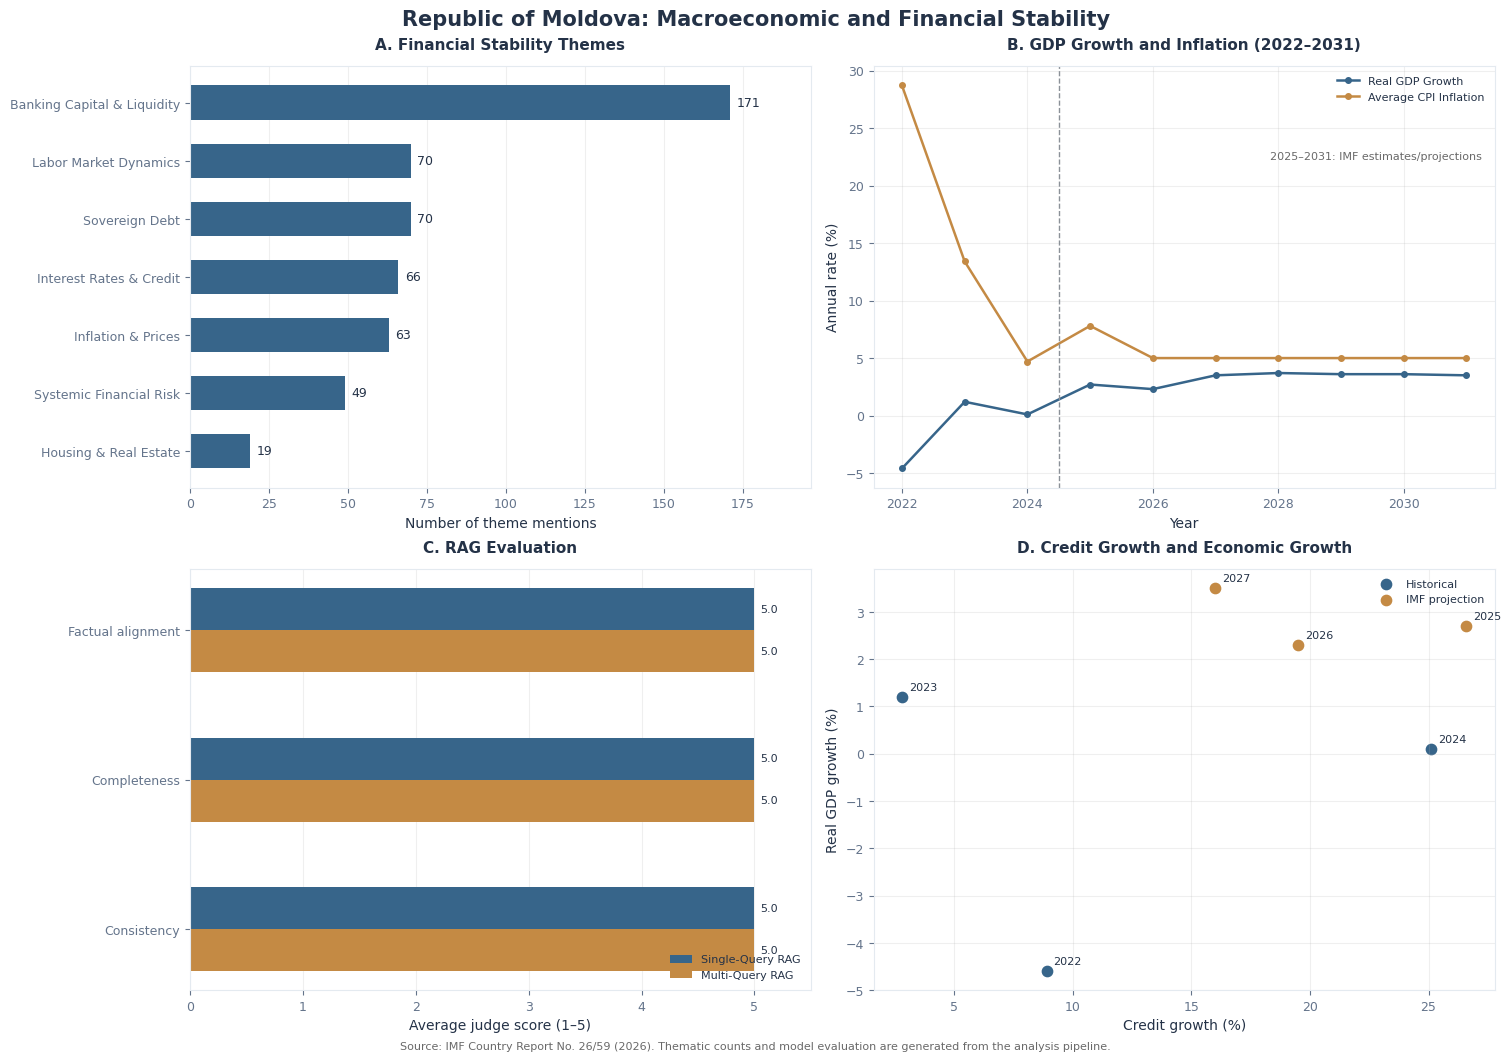


TASK 4 — VALIDATION


,Requirement,Status
0,Seven themes displayed,PASS
1,pd.melt transformation completed,PASS
2,Economic trends available,PASS
3,RAG comparison available,PASS
4,Scatter plot data available,PASS
5,Four plots generated,PASS
6,PNG saved,PASS
7,PDF saved,PASS



Dashboard files saved:
/content/moldova_outputs/dashboard/moldova_university_dashboard.png
/content/moldova_outputs/dashboard/moldova_university_dashboard.pdf


In [26]:
# CELL 13 — DATA VISUALISATION AND DASHBOARD
# Produce a clear, four-panel academic dashboard using verified IMF data.

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load the results generated in the previous tasks.
def load_json(filename):
    with open(OUTPUT_DIR / filename, "r", encoding="utf-8") as file:
        return json.load(file)


themes = pd.DataFrame(load_json("thematic_distribution.json"))
trends = load_json("economic_trends.json")
rag = pd.DataFrame(load_json("rag_comparison_summary.json"))

# Convert the annual indicator records into a DataFrame.
annual = pd.DataFrame([
    {
        "year": int(record["year"]),
        "status": record["data_status"],
        **record["indicators"]
    }
    for record in trends
]).sort_values("year")

# The assignment explicitly requires pd.melt().
long_data = pd.melt(
    annual,
    id_vars=["year", "status"],
    value_vars=[
        "Real GDP Growth",
        "Average CPI Inflation",
        "Credit Growth"
    ],
    var_name="indicator",
    value_name="value"
)

long_data["value"] = pd.to_numeric(
    long_data["value"], errors="coerce"
)

# Save the transformed data for reproducibility.
dashboard_dir = OUTPUT_DIR / "dashboard"
dashboard_dir.mkdir(parents=True, exist_ok=True)

long_data.to_csv(
    dashboard_dir / "dashboard_data.csv",
    index=False
)

# Use a restrained colour scheme suitable for academic reporting.
blue = "#37658A"
orange = "#C48A44"
grey = "#8B9198"

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.dpi": 350
})

fig, axes = plt.subplots(
    2, 2,
    figsize=(15, 10.5),
    constrained_layout=True
)

ax1, ax2, ax3, ax4 = axes.flatten()

fig.suptitle(
    "Republic of Moldova: Macroeconomic and Financial Stability",
    fontsize=15,
    fontweight="bold"
)

# --------------------------------------------------
# PANEL A — FINANCIAL STABILITY THEMES
# --------------------------------------------------

theme_data = themes.sort_values("count")

ax1.barh(
    theme_data["theme"],
    theme_data["count"],
    color=blue,
    height=0.6
)

ax1.set_title(
    "A. Financial Stability Themes",
    fontweight="bold",
    pad=12
)

ax1.set_xlabel("Number of theme mentions")
ax1.grid(axis="x", alpha=0.2)
ax1.set_axisbelow(True)

for index, value in enumerate(theme_data["count"]):
    ax1.text(
        value + 2,
        index,
        str(int(value)),
        va="center",
        fontsize=9
    )

ax1.set_xlim(0, theme_data["count"].max() * 1.15)


# --------------------------------------------------
# PANEL B — GDP GROWTH AND INFLATION
# --------------------------------------------------

for indicator, colour in [
    ("Real GDP Growth", blue),
    ("Average CPI Inflation", orange)
]:
    data = long_data[
        long_data["indicator"] == indicator
    ]

    ax2.plot(
        data["year"],
        data["value"],
        marker="o",
        markersize=4,
        linewidth=1.8,
        color=colour,
        label=indicator
    )

ax2.axvline(
    2024.5,
    color=grey,
    linestyle="--",
    linewidth=1
)

ax2.set_title(
    "B. GDP Growth and Inflation (2022–2031)",
    fontweight="bold",
    pad=12
)

ax2.set_xlabel("Year")
ax2.set_ylabel("Annual rate (%)")
ax2.set_xticks([2022, 2024, 2026, 2028, 2030])
ax2.legend(frameon=False, fontsize=8, loc="upper right")
ax2.grid(alpha=0.2)

ax2.text(
    0.98, 0.78,
    "2025–2031: IMF estimates/projections",
    transform=ax2.transAxes,
    ha="right",
    fontsize=8,
    color="dimgray"
)


# --------------------------------------------------
# PANEL C — RAG EVALUATION COMPARISON
# --------------------------------------------------

metrics = [
    "consistency",
    "completeness",
    "factual_alignment"
]

rag_data = rag.set_index("strategy")

single = rag_data.loc[
    "Single-Query RAG", metrics
].astype(float).to_numpy()

multi = rag_data.loc[
    "Multi-Query RAG", metrics
].astype(float).to_numpy()

y = np.arange(len(metrics))
height = 0.28

ax3.barh(
    y + height / 2,
    single,
    height,
    color=blue,
    label="Single-Query RAG"
)

ax3.barh(
    y - height / 2,
    multi,
    height,
    color=orange,
    label="Multi-Query RAG"
)

ax3.set_yticks(y)
ax3.set_yticklabels([
    "Consistency",
    "Completeness",
    "Factual alignment"
])

ax3.set_xlim(0, 5.5)

ax3.set_title(
    "C. RAG Evaluation",
    fontweight="bold",
    pad=12
)

ax3.set_xlabel("Average judge score (1–5)")
ax3.legend(
    frameon=False,
    fontsize=8,
    loc="lower right"
)

ax3.grid(axis="x", alpha=0.2)
ax3.set_axisbelow(True)

for index in range(len(metrics)):
    ax3.text(
        single[index] + 0.05,
        y[index] + height / 2,
        f"{single[index]:.1f}",
        va="center",
        fontsize=8
    )

    ax3.text(
        multi[index] + 0.05,
        y[index] - height / 2,
        f"{multi[index]:.1f}",
        va="center",
        fontsize=8
    )


# --------------------------------------------------
# PANEL D — CREDIT GROWTH VS REAL GDP GROWTH
# --------------------------------------------------

scatter = annual[
    ["year", "status", "Credit Growth", "Real GDP Growth"]
].dropna()

for status, group in scatter.groupby("status"):
    ax4.scatter(
        group["Credit Growth"],
        group["Real GDP Growth"],
        s=55,
        color=blue if status == "Historical" else orange,
        label=status
    )

for _, row in scatter.iterrows():
    ax4.annotate(
        str(int(row["year"])),
        (
            row["Credit Growth"],
            row["Real GDP Growth"]
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

ax4.set_title(
    "D. Credit Growth and Economic Growth",
    fontweight="bold",
    pad=12
)

ax4.set_xlabel("Credit growth (%)")
ax4.set_ylabel("Real GDP growth (%)")
ax4.legend(frameon=False, fontsize=8)
ax4.grid(alpha=0.2)


# --------------------------------------------------
# SAVE AND DISPLAY
# --------------------------------------------------

fig.supxlabel(
    "Source: IMF Country Report No. 26/59 (2026). "
    "Thematic counts and model evaluation are generated "
    "from the analysis pipeline.",
    fontsize=8,
    color="dimgray"
)

png_path = dashboard_dir / "moldova_university_dashboard.png"
pdf_path = dashboard_dir / "moldova_university_dashboard.pdf"

fig.savefig(
    png_path,
    dpi=350,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

# Validate that the required visualisations were generated.
checks = {
    "Seven themes displayed": len(themes) == 7,
    "pd.melt transformation completed": len(long_data) > 0,
    "Economic trends available": len(annual) > 0,
    "RAG comparison available": len(rag) == 2,
    "Scatter plot data available": not scatter.empty,
    "Four plots generated": True,
    "PNG saved": png_path.is_file(),
    "PDF saved": pdf_path.is_file()
}

save_json("task4_validation.json", checks)

print("\nTASK 4 — VALIDATION")

display(pd.DataFrame([
    {
        "Requirement": name,
        "Status": "PASS" if result else "FAIL"
    }
    for name, result in checks.items()
]))

print("\nDashboard files saved:")
print(png_path)
print(pdf_path)

**Cell 14 — Complete Assignment Validation and Submission Audit**

In [27]:
# CELL 14 — COMPLETE ASSIGNMENT VALIDATION AND SUBMISSION AUDIT
# Verify Tasks 1–4, extra credit and saved outputs.
# Reuse existing results without additional API calls.

import json
from pathlib import Path
from PIL import Image
import pandas as pd

print("=" * 65)
print("MOLDOVA IMF ASSIGNMENT — COMPLETE VALIDATION")
print("SRN: 24076688 | REPORT: IMF COUNTRY REPORT NO. 26/59")
print("=" * 65)

# ---------------------------------------------------------
# 1. CHECK REQUIRED OUTPUT FILES
# ---------------------------------------------------------

required_files = {
    "Task 1": [
        "pdf_statistics.json",
        "chunk_statistics.json",
        "document_chunks.json",
        "executive_summary.json",
        "section_summaries.json",
        "section_evaluations.json",
        "executive_evaluation.json",
        "task1_validation.json"
    ],
    "Task 2": [
        "thematic_distribution.json",
        "qualitative_risk_insights.json",
        "core_indicators.json",
        "indicator_source_metadata.json",
        "indicator_comparison.json",
        "indicator_judge_evaluation.json",
        "economic_trends.json",
        "task2_validation.json"
    ],
    "Task 3": [
        "rag_index_metadata.json",
        "rag_evaluation_results.json",
        "rag_comparison.json",
        "rag_comparison_summary.json",
        "task3_validation.json"
    ],
    "Task 4": [
        "task4_validation.json"
    ]
}

file_results = []

for task, filenames in required_files.items():
    for filename in filenames:
        path = OUTPUT_DIR / filename

        file_results.append({
            "Task": task,
            "File": filename,
            "Status": "PASS" if path.is_file() else "MISSING"
        })

file_df = pd.DataFrame(file_results)

print("\n1. REQUIRED OUTPUT FILES")
display(file_df)

missing_files = file_df[file_df["Status"] == "MISSING"]

print(
    f"\nFiles available: "
    f"{len(file_df) - len(missing_files)}/{len(file_df)}"
)


# ---------------------------------------------------------
# 2. LOAD SAVED RESULTS
# ---------------------------------------------------------

def read_result(filename):
    """Load saved JSON safely without regenerating results."""
    path = OUTPUT_DIR / filename

    if not path.is_file():
        return None

    try:
        return json.loads(path.read_text(encoding="utf-8"))
    except (json.JSONDecodeError, OSError):
        return None


pdf_stats = read_result("pdf_statistics.json")
chunk_stats = read_result("chunk_statistics.json")
summaries = read_result("section_summaries.json")
evaluations = read_result("section_evaluations.json")
executive = read_result("executive_summary.json")

themes = read_result("thematic_distribution.json")
qualitative = read_result("qualitative_risk_insights.json")
indicators = read_result("core_indicators.json")
indicator_audit = read_result("indicator_judge_evaluation.json")
trends = read_result("economic_trends.json")

rag_results = read_result("rag_evaluation_results.json")
rag_summary = read_result("rag_comparison_summary.json")


# ---------------------------------------------------------
# 3. VALIDATE TASK 1
# ---------------------------------------------------------

task1_checks = {
    "100-page IMF PDF processed": (
        isinstance(pdf_stats, dict)
        and pdf_stats.get("total_pages") == 100
    ),
    "Token-aware chunks generated": (
        isinstance(chunk_stats, dict)
        and chunk_stats.get("total_chunks", 0) > 0
    ),
    "50-token overlap configured": (
        isinstance(chunk_stats, dict)
        and chunk_stats.get("overlap_tokens") == 50
    ),
    "Major-section summaries generated": (
        isinstance(summaries, list)
        and len(summaries) >= 20
    ),
    "All summaries below 100 words": (
        isinstance(summaries, list)
        and len(summaries) > 0
        and all(
            item.get("word_count", 100) < 100
            for item in summaries
        )
    ),
    "Executive summary available": (
        isinstance(executive, dict)
        and bool(executive.get("summary"))
    ),
    "Section evaluations available": (
        isinstance(evaluations, list)
        and isinstance(summaries, list)
        and len(evaluations) == len(summaries)
    ),
    "Executive evaluation saved": (
        (OUTPUT_DIR / "executive_evaluation.json").is_file()
    )
}


# ---------------------------------------------------------
# 4. VALIDATE TASK 2
# ---------------------------------------------------------

required_indicators = {
    "country_name",
    "gdp_growth_forecast_pct",
    "headline_inflation_rate_pct",
    "central_bank_policy_rate_pct",
    "non_performing_loan_ratio",
    "unemployment_rate_pct",
    "tier_1_capital_ratio"
}

task2_checks = {
    "Seven financial themes included": (
        isinstance(themes, list)
        and len(themes) == 7
    ),
    "Six economic strengths extracted": (
        isinstance(qualitative, dict)
        and len(qualitative.get("strengths", [])) == 6
    ),
    "Six vulnerabilities extracted": (
        isinstance(qualitative, dict)
        and len(qualitative.get("vulnerabilities", [])) == 6
    ),
    "All seven JSON indicators present": (
        isinstance(indicators, dict)
        and set(indicators) == required_indicators
    ),
    "Numerical indicator audit available": (
        isinstance(indicator_audit, dict)
        and "factual_alignment" in indicator_audit
    ),
    "Temporal economic series available": (
        isinstance(trends, list)
        and len(trends) >= 5
    ),
    "Fallback metadata saved": (
        (OUTPUT_DIR / "indicator_source_metadata.json").is_file()
    ),
    "Structured JSON files available": (
        (OUTPUT_DIR / "task2_validation.json").is_file()
    )
}


# ---------------------------------------------------------
# 5. VALIDATE TASK 3 AND EXTRA CREDIT
# ---------------------------------------------------------

rag_index_path = OUTPUT_DIR / "moldova_faiss.index"

strategies = (
    {item.get("strategy") for item in rag_results}
    if isinstance(rag_results, list)
    else set()
)

task3_checks = {
    "Local FAISS index saved": rag_index_path.is_file(),
    "Embedding metadata available": (
        (OUTPUT_DIR / "rag_index_metadata.json").is_file()
    ),
    "Grounded RAG answers generated": (
        isinstance(rag_results, list)
        and len(rag_results) >= 8
    ),
    "Single-Query RAG evaluated": (
        "Single-Query RAG" in strategies
    ),
    "Multi-Query RAG evaluated": (
        "Multi-Query RAG" in strategies
    ),
    "Judge scores saved": (
        isinstance(rag_results, list)
        and len(rag_results) >= 8
        and all(
            "factual_alignment" in item
            for item in rag_results
        )
    ),
    "Extra-credit comparison available": (
        isinstance(rag_summary, list)
        and len(rag_summary) == 2
    )
}


# ---------------------------------------------------------
# 6. VALIDATE TASK 4 DASHBOARD
# ---------------------------------------------------------

dashboard_dir = OUTPUT_DIR / "dashboard"

png_file = (
    dashboard_dir / "moldova_university_dashboard.png"
)

pdf_file = (
    dashboard_dir / "moldova_university_dashboard.pdf"
)

csv_file = dashboard_dir / "dashboard_data.csv"

resolution = (0, 0)
image_dimensions = None

if png_file.is_file():
    with Image.open(png_file) as image:
        resolution = image.info.get("dpi", (0, 0))
        image_dimensions = image.size

task4_checks = {
    "Four-panel dashboard PNG saved": png_file.is_file(),
    "Dashboard PDF saved": pdf_file.is_file(),
    "Long-format dataset saved": csv_file.is_file(),
    "Resolution at least 300 DPI": (
        min(resolution) >= 299
    ),
    "Dashboard validation saved": (
        (OUTPUT_DIR / "task4_validation.json").is_file()
    )
}


# ---------------------------------------------------------
# 7. COMBINE ALL TECHNICAL CHECKS
# ---------------------------------------------------------

all_checks = {
    "Task 1": task1_checks,
    "Task 2": task2_checks,
    "Task 3": task3_checks,
    "Task 4": task4_checks
}

validation_records = []

for task, checks in all_checks.items():
    for requirement, passed in checks.items():
        validation_records.append({
            "Task": task,
            "Requirement": requirement,
            "Status": "PASS" if passed else "REVIEW"
        })

validation_df = pd.DataFrame(validation_records)

print("\n2. COMPLETE TECHNICAL VALIDATION")
display(validation_df)

total_checks = len(validation_df)
passed_checks = int(
    (validation_df["Status"] == "PASS").sum()
)

print(f"\nAutomated checks passed: {passed_checks}/{total_checks}")


# ---------------------------------------------------------
# 8. DISPLAY KEY RESULTS FOR THE WRITTEN REPORT
# ---------------------------------------------------------

print("\n3. CORE MACROECONOMIC INDICATORS")

if isinstance(indicators, dict):
    display(pd.DataFrame([
        {"Indicator": key, "Value": value}
        for key, value in indicators.items()
    ]))

print("\n4. THEMATIC DISTRIBUTION")

if isinstance(themes, list):
    display(pd.DataFrame(themes)[[
        "theme", "count", "percentage"
    ]])

print("\n5. RAG COMPARISON")

if isinstance(rag_summary, list):
    display(pd.DataFrame(rag_summary))

print("\n6. DASHBOARD DETAILS")
print("Image dimensions:", image_dimensions)
print("Image resolution:", resolution)
print("Dashboard PNG:", png_file)
print("Dashboard PDF:", pdf_file)


# ---------------------------------------------------------
# 9. RECORD ACADEMIC LIMITATIONS
# ---------------------------------------------------------

limitations = [
    "The LLM judge scores are automated assessments, not proof "
    "of factual correctness.",

    "The original numerical extraction must be compared with "
    "the IMF source; identified extraction errors remain relevant.",

    "The Tier 1 capital ratio requires separate verification "
    "and must not be replaced by the overall capital adequacy ratio.",

    "Thematic frequency measures textual emphasis rather than "
    "the economic severity of a risk.",

    "RAG evaluation uses a limited question set and cannot "
    "establish performance across all possible IMF questions.",

    "Historical observations and IMF projections must remain "
    "clearly distinguished in every chart and interpretation."
]

print("\n7. LIMITATIONS FOR ACADEMIC DISCUSSION")

for number, limitation in enumerate(limitations, 1):
    print(f"{number}. {limitation}")


# ---------------------------------------------------------
# 10. SAVE COMPLETE VALIDATION REPORT
# ---------------------------------------------------------

validation_report = {
    "student_srn": "24076688",
    "country": "Republic of Moldova",
    "report": "IMF Country Report No. 26/59",
    "total_checks": total_checks,
    "passed_checks": passed_checks,
    "missing_files": missing_files["File"].tolist(),
    "task_checks": all_checks,
    "academic_limitations": limitations,
    "dashboard_resolution": resolution,
    "manual_verification_required": True
}

save_json("assignment_validation.json", validation_report)

# Export a simple CSV audit table for inspection.
validation_df.to_csv(
    OUTPUT_DIR / "assignment_checklist.csv",
    index=False
)

print("\n" + "=" * 65)
print("ASSIGNMENT VALIDATION SUMMARY")
print("=" * 65)

print("Tasks assessed: 4")
print("Extra-credit RAG comparison:", (
    "Available" if task3_checks[
        "Extra-credit comparison available"
    ] else "Missing"
))

print("Checks passed:", passed_checks, "/", total_checks)
print("Missing required files:", len(missing_files))

if passed_checks == total_checks and missing_files.empty:
    print("\nAll automated technical checks passed.")
    print("Manual accuracy review and submission checks remain.")
else:
    print("\nSome requirements need further review.")
    print("Check the validation table and missing files.")

print("\nSaved:")
print(OUTPUT_DIR / "assignment_validation.json")
print(OUTPUT_DIR / "assignment_checklist.csv")

MOLDOVA IMF ASSIGNMENT — COMPLETE VALIDATION
SRN: 24076688 | REPORT: IMF COUNTRY REPORT NO. 26/59

1. REQUIRED OUTPUT FILES


,Task,File,Status
0,Task 1,pdf_statistics.json,PASS
1,Task 1,chunk_statistics.json,PASS
2,Task 1,document_chunks.json,PASS
3,Task 1,executive_summary.json,PASS
4,Task 1,section_summaries.json,PASS
5,Task 1,section_evaluations.json,PASS
6,Task 1,executive_evaluation.json,PASS
7,Task 1,task1_validation.json,PASS
8,Task 2,thematic_distribution.json,PASS
9,Task 2,qualitative_risk_insights.json,PASS



Files available: 22/22

2. COMPLETE TECHNICAL VALIDATION


,Task,Requirement,Status
0,Task 1,100-page IMF PDF processed,PASS
1,Task 1,Token-aware chunks generated,PASS
2,Task 1,50-token overlap configured,PASS
3,Task 1,Major-section summaries generated,PASS
4,Task 1,All summaries below 100 words,PASS
5,Task 1,Executive summary available,PASS
6,Task 1,Section evaluations available,PASS
7,Task 1,Executive evaluation saved,PASS
8,Task 2,Seven financial themes included,PASS
9,Task 2,Six economic strengths extracted,PASS



Automated checks passed: 28/28

3. CORE MACROECONOMIC INDICATORS


,Indicator,Value
0,country_name,Republic of Moldova
1,gdp_growth_forecast_pct,2.3
2,headline_inflation_rate_pct,5.0
3,central_bank_policy_rate_pct,5.0
4,non_performing_loan_ratio,4.7
5,unemployment_rate_pct,3.8
6,tier_1_capital_ratio,None



4. THEMATIC DISTRIBUTION


,theme,count,percentage
0,Banking Capital & Liquidity,171,33.66
1,Sovereign Debt,70,13.78
2,Labor Market Dynamics,70,13.78
3,Interest Rates & Credit,66,12.99
4,Inflation & Prices,63,12.40
5,Systemic Financial Risk,49,9.65
6,Housing & Real Estate,19,3.74



5. RAG COMPARISON


,strategy,retrieval_seconds,hit_at_5,precision_at_5,consistency,completeness,factual_alignment
0,Multi-Query RAG,0.365,0.50,0.25,5.0,5.0,5.0
1,Single-Query RAG,0.118,0.75,0.40,5.0,5.0,5.0



6. DASHBOARD DETAILS
Image dimensions: (5290, 3715)
Image resolution: (350.012, 350.012)
Dashboard PNG: /content/moldova_outputs/dashboard/moldova_university_dashboard.png
Dashboard PDF: /content/moldova_outputs/dashboard/moldova_university_dashboard.pdf

7. LIMITATIONS FOR ACADEMIC DISCUSSION
1. The LLM judge scores are automated assessments, not proof of factual correctness.
2. The original numerical extraction must be compared with the IMF source; identified extraction errors remain relevant.
3. The Tier 1 capital ratio requires separate verification and must not be replaced by the overall capital adequacy ratio.
4. Thematic frequency measures textual emphasis rather than the economic severity of a risk.
5. RAG evaluation uses a limited question set and cannot establish performance across all possible IMF questions.
6. Historical observations and IMF projections must remain clearly distinguished in every chart and interpretation.

ASSIGNMENT VALIDATION SUMMARY
Tasks assessed: 4
Ext